Description...

In [1]:
import sys
sys.path.append('/lhome/ific/c/ccortesp/Analysis/')

from libs import crudo

from   iminuit import Minuit
from   iminuit.cost import LeastSquares
from matplotlib.gridspec import GridSpec
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from   scipy.optimize import curve_fit
from   scipy.signal import find_peaks
import yaml

# Styling Plot
# crudo.pt.papers_plot_style()
crudo.pt.ccortesp_plot_style()
# PRELIM_LOGO = np.asarray(Image.open('/lhome/ific/c/ccortesp/Analysis/images/next_logo_preliminary.png'))

%matplotlib inline
%load_ext autoreload
%autoreload 2

# Runs Configuration

In [5]:
# RUNS_TO_CHECK = [14840, 16116, 16158]
# RUNS_TO_CHECK = [16089, 16090, 16105, 16114, 16116, 16121]
# RUNS_TO_CHECK = [14739, 14840, 16166]
RUNS_TO_CHECK = [16186]
EXTRA_TAG = [None]
# EXTRA_TAG = [None, 'prod_fullbaseline', 'prod_shortbaseline']      # Options: None, '20260727', 'prod_cuts'
CRITERIA  = 'Xe'      # Options: 'Ar', 'Xe', 'Xe_vN'

RUNS_INFO_FILENAME = "/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/utilities/runs_information.csv"
BASE_PATH = '/lhome/ific/c/ccortesp/Data/Cmmssnng/h5/'

In [6]:
RUNS_INFO_DF = pd.read_csv(RUNS_INFO_FILENAME, index_col="run_number").reset_index()
RUNS_INFO_DF = RUNS_INFO_DF[RUNS_INFO_DF["run_number"].isin(RUNS_TO_CHECK)].copy()
RUNS_INFO_DF

,run_number,pressure,cath_voltage,gate_voltage,duration,OK,LOST,isotope
27,16186,8.928,32996.7,9401.6,90422.0,1803640.0,2358607.0,Xe


# Selected Data

In [7]:
SEL_DICT = {}

print('Loading selected data for:')
for run_id in RUNS_INFO_DF['run_number']:

    for tag in EXTRA_TAG:
        # Construct a clean, descriptive dictionary key
        key = f"{run_id}_v{tag}" if tag is not None else f"{run_id}"
        print(f"  - Run {key}")

        # Load and assign the data
        doro_df = pd.read_hdf(os.path.join(BASE_PATH, 'run_' + key + '_selected_' + CRITERIA + '.h5'), key='DST/Events')
        # soph_df = pd.read_hdf(os.path.join(BASE_PATH, 'run_' + key + '_selected_' + CRITERIA + '.h5'), key='RECO/Events')

        SEL_DICT[key] = {}
        SEL_DICT[key]['doro_df'] = doro_df
        # SEL_DICT[key]['soph_df'] = soph_df

Loading selected data for:
  - Run 16186


Construct the _active volume_ mask to avoid the cathode

In [8]:
EXTRA_INFO = {}
ALPHA_CUT = 1400

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    run_id = int(key.split('_')[0])

    doro_df = SEL_DICT[key]['doro_df']

    cath_lim = crudo.tf.get_cathode_limit(doro_df, n_bins=80, step_back=1)
    # cath_lim = doro_df['DT'].max()
    z_mask    = (doro_df['DT'] >= 0) & (doro_df['DT'] < cath_lim)
    cath_mask = (doro_df['DT'] >= cath_lim)
    rad_mask  = (doro_df['R'] <= 400)
    alpha_mask = (doro_df['S1e_corr'] >= ALPHA_CUT)

    # Special mask for better energy resolution
    if run_id in [14739, 14840]:
        w2_mask = (doro_df['S2w'] >= 85) & (doro_df['S2w'] <= 150)

    elif run_id in [16116]:
        w2_mask = (doro_df['S2w'] >= 110) & (doro_df['S2w'] <= 200)

    elif run_id in [16158]:
        w2_mask = (doro_df['S2w'] >= 60) & (doro_df['S2w'] <= 120)

    w1_mask = (doro_df['S1w'] < 350)


    EXTRA_INFO[key] = { 'cath_lim'   : cath_lim
                      , 'AV_Z_mask'  : z_mask
                      , 'cath_mask'  : cath_mask
                      , 'rad_mask'   : rad_mask
                      , 'alpha_mask' : alpha_mask
                      , 'w1_mask'    : w1_mask
                    #   , 'w2_mask'    : w2_mask
                      }


Run 16186:
Cathode limit = 1466.35 μs


# Base Distributions (WITH CUTS!)

## $S1$ Pulse

### Energy

Run 16186:
  - S1 Energy | AV = [733.58, 4025.71] PE
  - S1 Energy | Cathode = [1412.90, 3271.22] PE


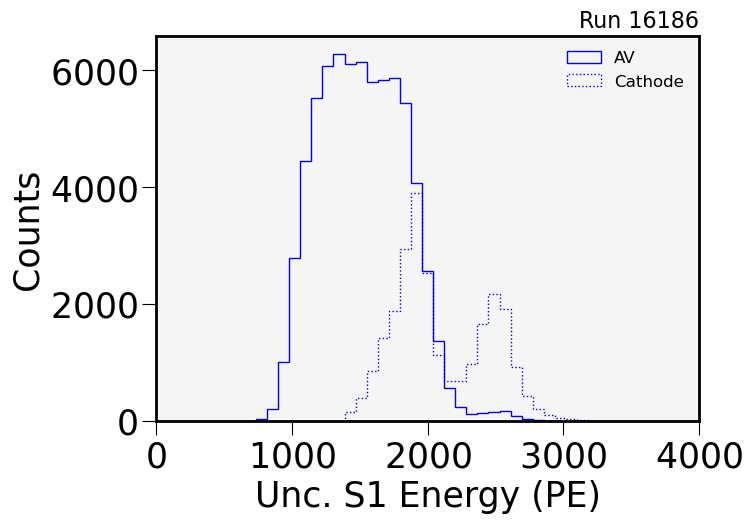

In [9]:
# Params
bins = np.linspace(0, 4e3, 50)
ls_style = ['-', ':']

for key in SEL_DICT.keys():

    print(f"Run {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    alpha_mask = EXTRA_INFO[key]['alpha_mask']
    for j, label in enumerate(['AV', 'Cathode']):

        if label == 'AV':
            mask = alpha_mask & EXTRA_INFO[key]['AV_Z_mask']
        
        elif label == 'Cathode':
            mask = alpha_mask & EXTRA_INFO[key]['cath_mask']


        if mask is not None:
            mask_df = doro_df[mask].copy()
        else:
            mask_df = doro_df.copy()    

        # Variables
        E1 = mask_df['S1e']
        print(f"  - S1 Energy | {label} = [{E1.min():.2f}, {E1.max():.2f}] PE")

        counts, _, _ = plt.hist(E1, bins=bins, histtype='step', color='blue', lw=1.0, ls=ls_style[j], label=label)

    # Plot
    plt.xlabel('Unc. S1 Energy (PE)')
    plt.ylabel('Counts')
    # plt.yscale('log')
    plt.xlim(bins[0], bins[-1])
    plt.legend(loc='upper right', fontsize=12)
    plt.title(f'Run {key}', loc='right', fontsize=16)

    # Cut line
    plt.axvline(x=4e3, c='gray', ls='--', lw=1)
    plt.axvline(x=300e3, c='gray', ls='--', lw=1)

    plt.gca().set_facecolor("whitesmoke")
    plt.show()

In [9]:
# # Params
# # Params
# bins = np.linspace(1e3, 3e3, 75)

# for key in SEL_DICT.keys():

#     print(f"Run {key}:")
#     doro_df = SEL_DICT[key]['doro_df']

#     # Masking    
#     mask = (EXTRA_INFO[key]['alpha_mask']) & (doro_df['R'] <= rad_lim) & (doro_df['DT'] >= dt_min) & (doro_df['DT'] <= cath_lim)
#     if mask is not None:
#         mask_df = doro_df[mask].copy()
#     else:
#         mask_df = doro_df.copy()

#     # Variables
#     E1 = mask_df['S1e']
#     print(f"  - S1 Energy = [{E1.min():.2f}, {E1.max():.2f}] μs")

#     # Histogram
#     counts, _, _ = plt.hist(E1, bins=bins, range=None, histtype='step', color='blue', lw=1.0)

#     # Plot
#     plt.xlabel('S1 Energy (PE)')
#     plt.ylabel('Counts')
#     # plt.yscale('log')
#     plt.xlim(bins[0], bins[-1]) 
#     # plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
#     plt.title(f'Run {key} | (DT = [{dt_min}, {cath_lim:.1f}] μs) + (R ≤ {rad_lim} mm)', loc='right', fontsize=12)

#     # Cut line
#     # plt.axvline(x=4e3, c='gray', ls='--', lw=1)
#     # plt.axvline(x=300e3, c='gray', ls='--', lw=1)

#     plt.gca().set_facecolor("whitesmoke")
#     plt.show()

### Height

Run 16186:
  - S1 Height = [33.41, 559.79] PE


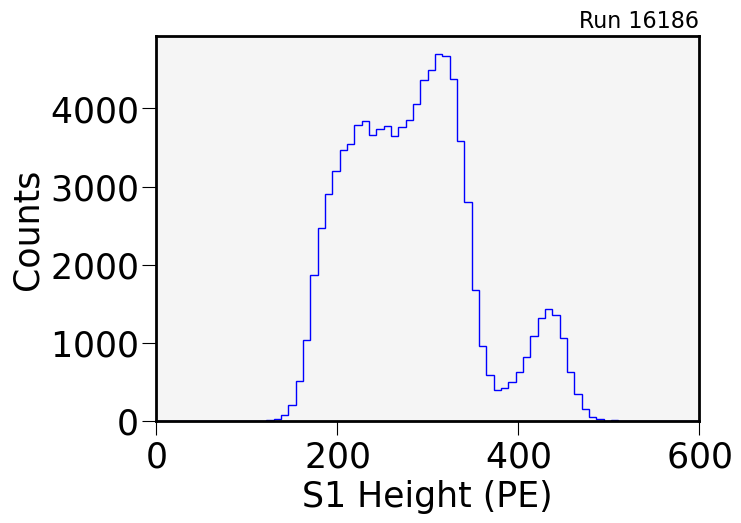

In [10]:
# Params
bins = np.linspace(0, 600, 75)

for key in SEL_DICT.keys():

    print(f"Run {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Masking    
    mask = (EXTRA_INFO[key]['alpha_mask']) #& (EXTRA_INFO[key]['AV_Z_mask'])
    if mask is not None:
        mask_df = doro_df[mask].copy()
    else:
        mask_df = doro_df.copy()

    # Variables
    H1 = mask_df['S1h']
    print(f"  - S1 Height = [{H1.min():.2f}, {H1.max():.2f}] PE")
    # print(bins)

    # Histogram
    counts, _, _ = plt.hist(H1, bins=bins, histtype='step', color='blue', lw=1.0)

    # Plot
    plt.xlabel('S1 Height (PE)')
    plt.ylabel('Counts')
    # plt.yscale('log')
    plt.xlim(bins[0], bins[-1])
    # plt.xticks(bins[::10])
    plt.title(f'Run {key}', loc='right', fontsize=16)

    # Cut line
    # plt.axvline(x=50, c='gray', ls='--', lw=1)
    # plt.axvline(x=500, c='gray', ls='--', lw=1)

    plt.gca().set_facecolor("whitesmoke")
    plt.show()

In [11]:
# # Params
# bins = np.linspace(0, 600, 75)


# for key in SEL_DICT.keys():

#     print(f"Run {key}:")
#     doro_df = SEL_DICT[key]['doro_df']

#     # Masking    
#     mask = (EXTRA_INFO[key]['alpha_mask']) & (doro_df['R'] <= rad_lim) & (doro_df['DT'] >= dt_min) & (doro_df['DT'] <= cath_lim)
#     if mask is not None:
#         mask_df = doro_df[mask].copy()
#     else:
#         mask_df = doro_df.copy()

#     # Variables
#     H1 = mask_df['S1h']
#     print(f"  - S1 Height = [{H1.min():.2f}, {H1.max():.2f}] μs")

#     # Histogram
#     counts, _, _ = plt.hist(H1, bins=bins, range=None, histtype='step', color='blue', lw=1.0)

#     # Plot
#     plt.xlabel('S1 Height (PE)')
#     plt.ylabel('Counts')
#     # plt.yscale('log')
#     plt.xlim(bins[0], bins[-1]) 
#     # plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
#     plt.title(f'Run {key} | (DT = [{dt_min}, {cath_lim:.1f}] μs) + (R ≤ {rad_lim} mm)', loc='right', fontsize=12)

#     # Cut line
#     # plt.axvline(x=4e3, c='gray', ls='--', lw=1)
#     # plt.axvline(x=300e3, c='gray', ls='--', lw=1)

#     plt.gca().set_facecolor("whitesmoke")
#     plt.show()

## $S2$ Pulse

### Energy

Run 16186:
  - S2 Energy = [40030.13, 867214.06] PE


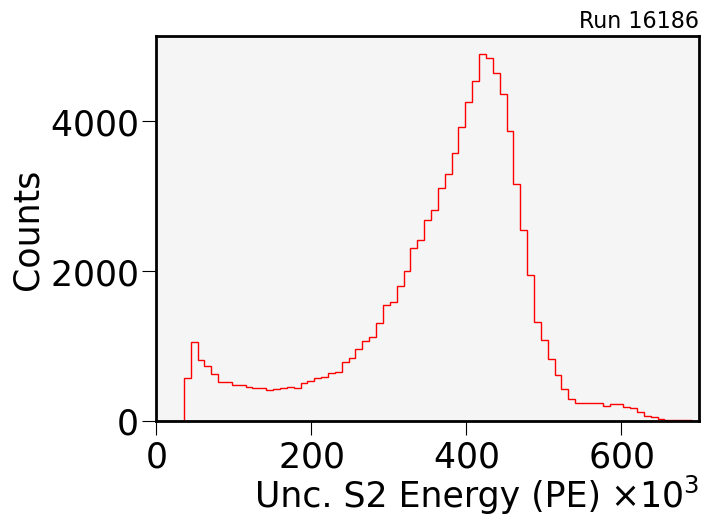

In [11]:
# Params
bins = np.linspace(0, 700e3, 80)

for key in SEL_DICT.keys():

    print(f"Run {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Masking    
    mask = (EXTRA_INFO[key]['alpha_mask']) #& (EXTRA_INFO[key]['AV_Z_mask'])
    if mask is not None:
        mask_df = doro_df[mask].copy()
    else:
        mask_df = doro_df.copy()

    # Variables
    E2 = mask_df['S2e']
    print(f"  - S2 Energy = [{E2.min():.2f}, {E2.max():.2f}] PE")

    counts, _, _ = plt.hist(E2, bins=bins, histtype='step', color='red', lw=1.0)

    # Plot
    plt.xlabel('Unc. S2 Energy (PE)')
    plt.ylabel('Counts')
    # plt.yscale('log')
    plt.xlim(bins[0], bins[-1])
    plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
    plt.title(f'Run {key}', loc='right', fontsize=16)

    plt.gca().set_facecolor("whitesmoke")
    plt.show()

In [14]:
# # Params
# # Params
# bins = np.linspace(0, 900e3, 75)

# for key in SEL_DICT.keys():

#     print(f"Run {key}:")
#     doro_df = SEL_DICT[key]['doro_df']

#     # Masking    
#     mask = (EXTRA_INFO[key]['alpha_mask']) & (doro_df['R'] <= rad_lim) & (doro_df['DT'] >= dt_min) & (doro_df['DT'] <= cath_lim)
#     if mask is not None:
#         mask_df = doro_df[mask].copy()
#     else:
#         mask_df = doro_df.copy()

#     # Variables
#     E2 = mask_df['S2e']
#     print(f"  - S2 Energy = [{E2.min():.2f}, {E2.max():.2f}] μs")

#     # Histogram
#     counts, _, _ = plt.hist(E2, bins=bins, range=None, histtype='step', color='red', lw=1.0)

#     # Plot
#     plt.xlabel('S2 Energy (PE)')
#     plt.ylabel('Counts')
#     # plt.yscale('log')
#     plt.xlim(bins[0], bins[-1]) 
#     plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
#     plt.title(f'Run {key} | (DT = [{dt_min}, {cath_lim:.1f}] μs) + (R ≤ {rad_lim} mm)', loc='right', fontsize=12)

#     # Cut line
#     # plt.axvline(x=4e3, c='gray', ls='--', lw=1)
#     # plt.axvline(x=300e3, c='gray', ls='--', lw=1)

#     plt.gca().set_facecolor("whitesmoke")
#     plt.show()

### Height

Run 16186:
  - S2 Height = [1986.75, 269756.16] μs


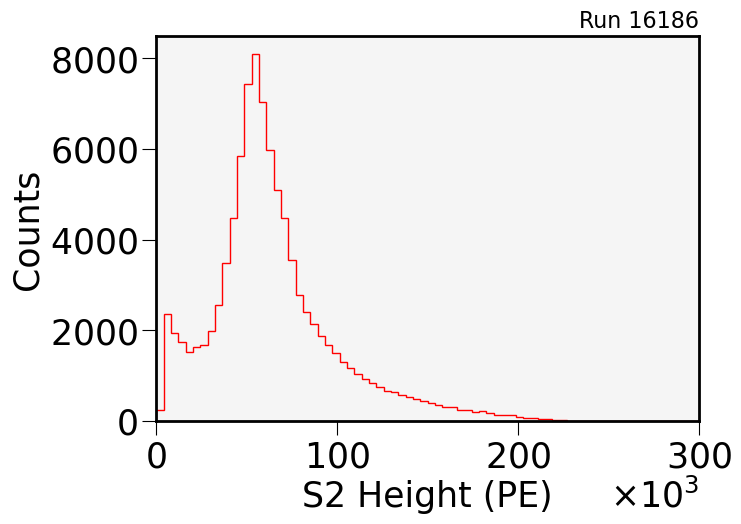

In [12]:
# Params
bins = np.linspace(0, 300e3, 75)  # In [μs]

for key in SEL_DICT.keys():

    print(f"Run {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Masking    
    mask = (EXTRA_INFO[key]['alpha_mask']) #& (EXTRA_INFO[key]['AV_Z_mask'])
    if mask is not None:
        mask_df = doro_df[mask].copy()
    else:
        mask_df = doro_df.copy()

    # Variables
    H2 = mask_df['S2h']
    print(f"  - S2 Height = [{H2.min():.2f}, {H2.max():.2f}] μs")
    # print(H2.describe())

    # Histogram
    counts, _, _ = plt.hist(H2, bins=bins, range=None, histtype='step', color='red', lw=1.0)

    # Plot
    plt.xlabel('S2 Height (PE)')
    plt.ylabel('Counts')
    # plt.yscale('log')
    plt.xlim(bins[0], bins[-1]) 
    plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
    plt.title(f'Run {key}', loc='right', fontsize=16)

    # Cut line
    # plt.axvline(x=4e3, c='gray', ls='--', lw=1)
    # plt.axvline(x=300e3, c='gray', ls='--', lw=1)

    plt.gca().set_facecolor("whitesmoke")
    plt.show()

In [16]:
# # Params
# bins = np.linspace(0, 100e3, 125)  # In [μs]

# for key in SEL_DICT.keys():

#     print(f"Run {key}:")
#     doro_df = SEL_DICT[key]['doro_df']

#     # Masking    
#     mask = (EXTRA_INFO[key]['alpha_mask']) & (doro_df['R'] <= rad_lim) & (doro_df['DT'] >= dt_min) & (doro_df['DT'] <= cath_lim)
#     if mask is not None:
#         mask_df = doro_df[mask].copy()
#     else:
#         mask_df = doro_df.copy()

#     # Variables
#     H2 = mask_df['S2h']
#     print(f"  - S2 Height = [{H2.min():.2f}, {H2.max():.2f}] μs")
#     # print(H2.describe())

#     # Histogram
#     counts, _, _ = plt.hist(H2, bins=bins, range=None, histtype='step', color='red', lw=1.0)

#     # Plot
#     plt.xlabel('S2 Height (PE)')
#     plt.ylabel('Counts')
#     # plt.yscale('log')
#     plt.xlim(bins[0], bins[-1]) 
#     plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
#     plt.title(f'Run {key} | (DT = [{dt_min}, {cath_lim:.1f}] μs) + (R ≤ {rad_lim} mm)', loc='right', fontsize=12)

#     # Cut line
#     # plt.axvline(x=4e3, c='gray', ls='--', lw=1)
#     # plt.axvline(x=300e3, c='gray', ls='--', lw=1)

#     plt.gca().set_facecolor("whitesmoke")
#     plt.show()

# Maps

## $S1$ Pulse

### Energy


Run 16186:


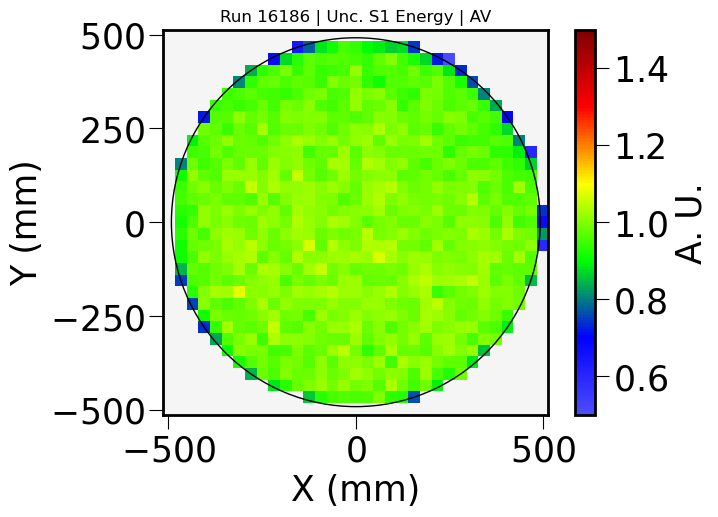

In [13]:
for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    run_id = int(key.split('_')[0])
    doro_df = SEL_DICT[key]['doro_df']

    # Masking    
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask'])
    if mask is not None:
        mask_df = doro_df[mask].copy()
    else:
        mask_df = doro_df.copy()

    # Variables    
    X = mask_df['X']
    Y = mask_df['Y']
    E1 = mask_df['S1e']

    # Map
    s1e_map, ex, ey = crudo.pt.mapping(X, Y, wei=E1, bin_scale=2, max_limit=crudo.pt.N100_rad, norm=True)
    s1e_map         = np.ma.masked_where(s1e_map==0, s1e_map)

    # Plot
    plt.pcolormesh(ex, ey, s1e_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.5, vmax=1.5)
    cbar = plt.colorbar(label='A. U.')
    cbar.set_ticks([0.6, 0.8, 1.0, 1.2, 1.4])
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.title (f'Run {key} | Unc. S1 Energy | AV', loc='center', fontsize=12) 

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    plt.show()


Run 16186:


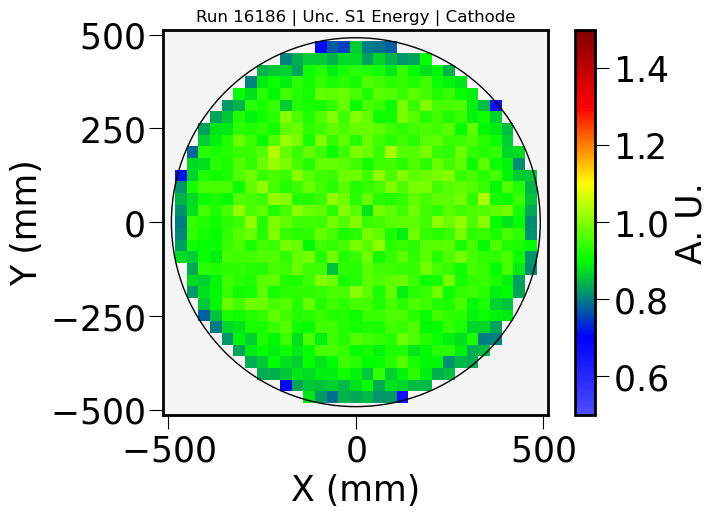

In [14]:
for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    run_id = int(key.split('_')[0])
    doro_df = SEL_DICT[key]['doro_df']

    # Masking    
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['cath_mask'])
    if mask is not None:
        mask_df = doro_df[mask].copy()
    else:
        mask_df = doro_df.copy()

    # Variables    
    X = mask_df['X']
    Y = mask_df['Y']
    E1 = mask_df['S1e']

    # Map
    s1e_map, ex, ey = crudo.pt.mapping(X, Y, wei=E1, bin_scale=2, max_limit=crudo.pt.N100_rad, norm=True)
    s1e_map         = np.ma.masked_where(s1e_map==0, s1e_map)

    # Plot
    plt.pcolormesh(ex, ey, s1e_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.5, vmax=1.5)
    cbar = plt.colorbar(label='A. U.')
    cbar.set_ticks([0.6, 0.8, 1.0, 1.2, 1.4])
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.title (f'Run {key} | Unc. S1 Energy | Cathode', loc='center', fontsize=12) 

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    plt.show()

### Height


Run 16186:


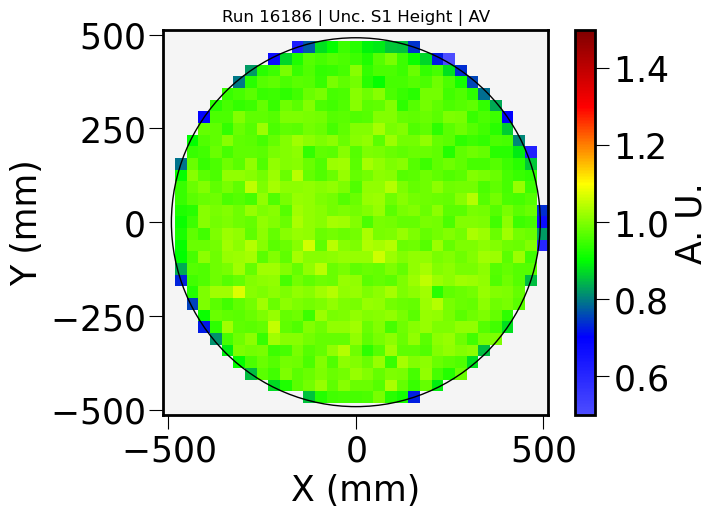

In [15]:
for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    run_id = int(key.split('_')[0])
    doro_df = SEL_DICT[key]['doro_df']

    # Masking    
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask'])
    if mask is not None:
        mask_df = doro_df[mask].copy()
    else:
        mask_df = doro_df.copy()

    # Variables    
    X = mask_df['X']
    Y = mask_df['Y']
    H1 = mask_df['S1h']

    # Map
    s1e_map, ex, ey = crudo.pt.mapping(X, Y, wei=H1, bin_scale=2, max_limit=crudo.pt.N100_rad, norm=True)
    s1e_map         = np.ma.masked_where(s1e_map==0, s1e_map)

    # Plot
    plt.pcolormesh(ex, ey, s1e_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.5, vmax=1.5)
    cbar = plt.colorbar(label='A. U.')
    cbar.set_ticks([0.6, 0.8, 1.0, 1.2, 1.4])
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.title (f'Run {key} | Unc. S1 Height | AV', loc='center', fontsize=12) 

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    plt.show()


Run 16186:


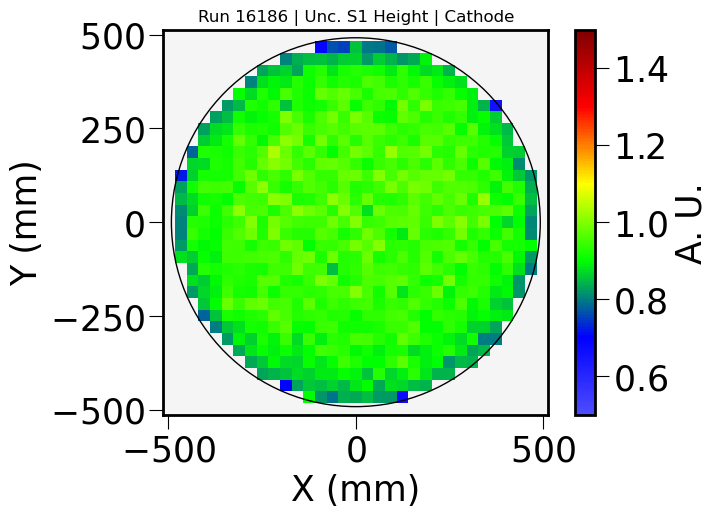

In [16]:
for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    run_id = int(key.split('_')[0])
    doro_df = SEL_DICT[key]['doro_df']

    # Masking    
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['cath_mask'])
    if mask is not None:
        mask_df = doro_df[mask].copy()
    else:
        mask_df = doro_df.copy()

    # Variables    
    X = mask_df['X']
    Y = mask_df['Y']
    H1 = mask_df['S1h']

    # Map
    s1e_map, ex, ey = crudo.pt.mapping(X, Y, wei=H1, bin_scale=2, max_limit=crudo.pt.N100_rad, norm=True)
    s1e_map         = np.ma.masked_where(s1e_map==0, s1e_map)

    # Plot
    plt.pcolormesh(ex, ey, s1e_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.5, vmax=1.5)
    cbar = plt.colorbar(label='A. U.')
    cbar.set_ticks([0.6, 0.8, 1.0, 1.2, 1.4])
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.title (f'Run {key} | Unc. S1 Height | Cathode', loc='center', fontsize=12) 

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    plt.show()

## $S2$ Pulse

### Energy


Run 16186:


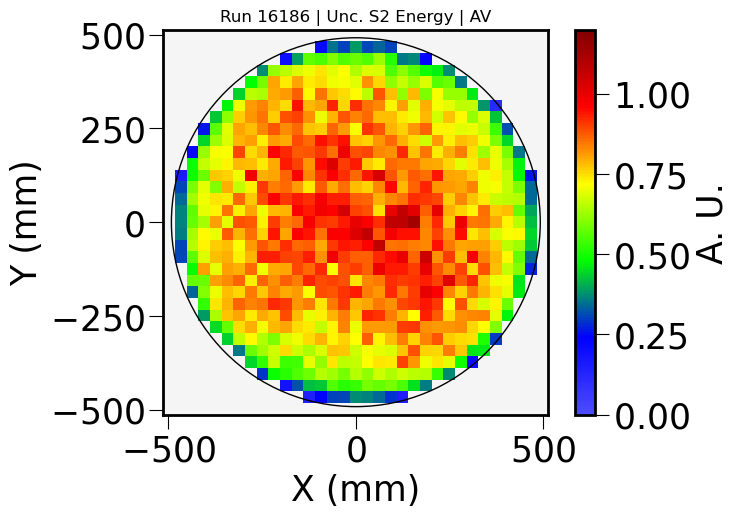

In [17]:
for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    run_id = int(key.split('_')[0])
    doro_df = SEL_DICT[key]['doro_df']

    # Masking    
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['cath_mask'])
    if mask is not None:
        mask_df = doro_df[mask].copy()
    else:
        mask_df = doro_df.copy()

    # Variables    
    X = mask_df['X']
    Y = mask_df['Y']
    E2 = mask_df['S2e']

    # Map
    s1e_map, ex, ey = crudo.pt.mapping(X, Y, wei=E2, bin_scale=2, max_limit=crudo.pt.N100_rad, norm=True)
    s1e_map         = np.ma.masked_where(s1e_map==0, s1e_map)

    # Plot
    plt.pcolormesh(ex, ey, s1e_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0, vmax=1.2)
    cbar = plt.colorbar(label='A. U.')
    # cbar.set_ticks([0.6, 0.8, 1.0, 1.2, 1.4])
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.title (f'Run {key} | Unc. S2 Energy | AV', loc='center', fontsize=12) 

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    plt.show()


Run 16186:


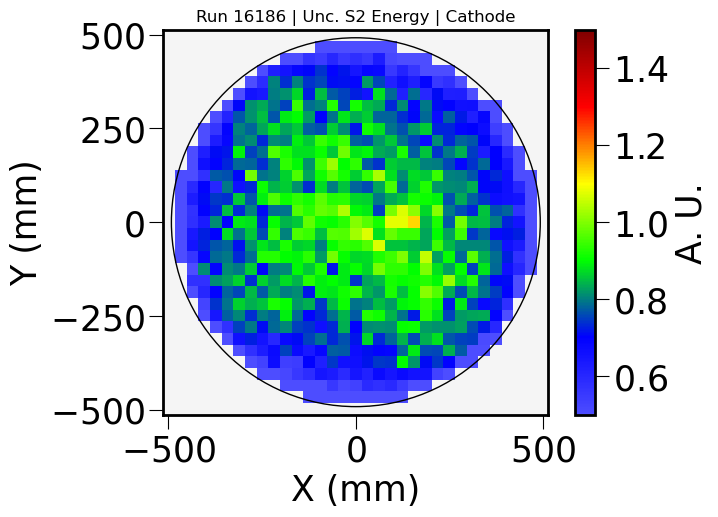

In [18]:
for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    run_id = int(key.split('_')[0])
    doro_df = SEL_DICT[key]['doro_df']

    # Masking    
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['cath_mask'])
    if mask is not None:
        mask_df = doro_df[mask].copy()
    else:
        mask_df = doro_df.copy()

    # Variables    
    X = mask_df['X']
    Y = mask_df['Y']
    E2 = mask_df['S2e']

    # Map
    s1e_map, ex, ey = crudo.pt.mapping(X, Y, wei=E2, bin_scale=2, max_limit=crudo.pt.N100_rad, norm=True)
    s1e_map         = np.ma.masked_where(s1e_map==0, s1e_map)

    # Plot
    plt.pcolormesh(ex, ey, s1e_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.5, vmax=1.5)
    cbar = plt.colorbar(label='A. U.')
    cbar.set_ticks([0.6, 0.8, 1.0, 1.2, 1.4])
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.title (f'Run {key} | Unc. S2 Energy | Cathode', loc='center', fontsize=12) 

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    plt.show()

### Height


Run 16186:


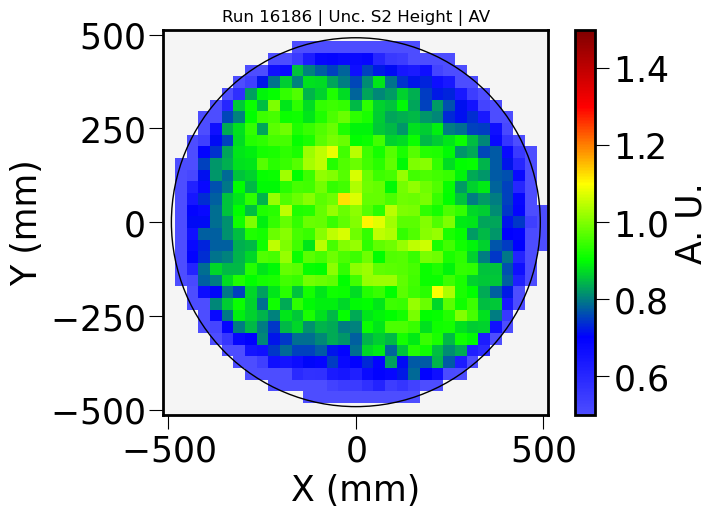

In [19]:
for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    run_id = int(key.split('_')[0])
    doro_df = SEL_DICT[key]['doro_df']

    # Masking    
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask'])
    if mask is not None:
        mask_df = doro_df[mask].copy()
    else:
        mask_df = doro_df.copy()

    # Variables    
    X = mask_df['X']
    Y = mask_df['Y']
    H2 = mask_df['S2h']

    # Map
    s1e_map, ex, ey = crudo.pt.mapping(X, Y, wei=H2, bin_scale=2, max_limit=crudo.pt.N100_rad, norm=True)
    s1e_map         = np.ma.masked_where(s1e_map==0, s1e_map)

    # Plot
    plt.pcolormesh(ex, ey, s1e_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.5, vmax=1.5)
    cbar = plt.colorbar(label='A. U.')
    cbar.set_ticks([0.6, 0.8, 1.0, 1.2, 1.4])
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.title (f'Run {key} | Unc. S2 Height | AV', loc='center', fontsize=12) 

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    plt.show()


Run 16186:


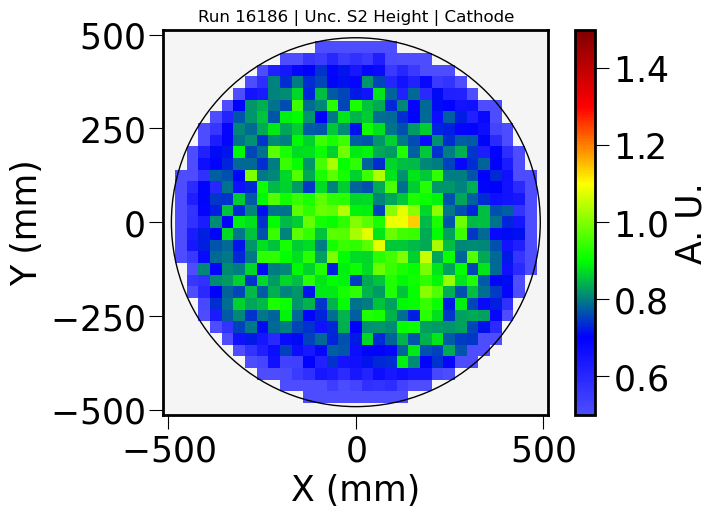

In [20]:
for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    run_id = int(key.split('_')[0])
    doro_df = SEL_DICT[key]['doro_df']

    # Masking    
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['cath_mask'])
    if mask is not None:
        mask_df = doro_df[mask].copy()
    else:
        mask_df = doro_df.copy()

    # Variables    
    X = mask_df['X']
    Y = mask_df['Y']
    H2 = mask_df['S2h']

    # Map
    s1e_map, ex, ey = crudo.pt.mapping(X, Y, wei=H2, bin_scale=2, max_limit=crudo.pt.N100_rad, norm=True)
    s1e_map         = np.ma.masked_where(s1e_map==0, s1e_map)

    # Plot
    plt.pcolormesh(ex, ey, s1e_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.5, vmax=1.5)
    cbar = plt.colorbar(label='A. U.')
    cbar.set_ticks([0.6, 0.8, 1.0, 1.2, 1.4])
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.title (f'Run {key} | Unc. S2 Height | Cathode', loc='center', fontsize=12) 

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    plt.show()

# 2D Histograms

### $S2h$ vs DT

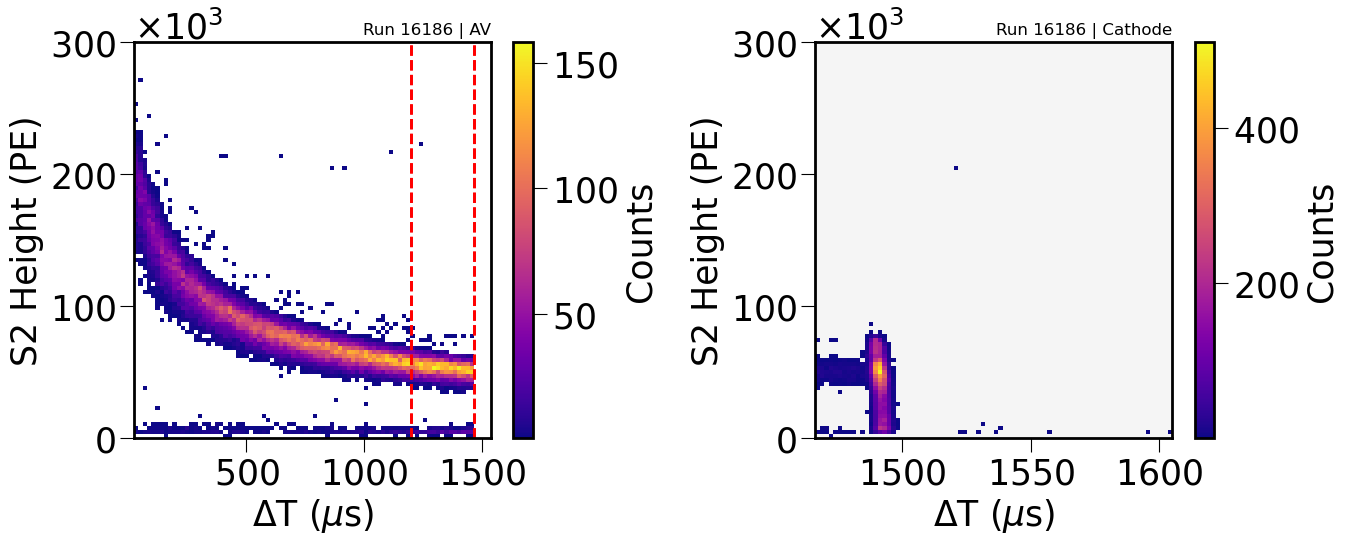

In [21]:
y_bins = np.linspace(0, 300e3, 100)

for key in SEL_DICT.keys():

    doro_df = SEL_DICT[key]['doro_df']

    fig = plt.figure(figsize=(14, 6))
    gs = GridSpec(1, 2, figure=fig)
    ax_left  = fig.add_subplot(gs[0, 0])
    ax_right = fig.add_subplot(gs[0, 1])

    for i, label in enumerate(['AV', 'Cathode']):

        base_mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['rad_mask'])
        if label == 'AV':
            mask = base_mask & (EXTRA_INFO[key]['AV_Z_mask'])
            ax = ax_left
        else:
            mask = base_mask & (EXTRA_INFO[key]['cath_mask'])
            ax = ax_right

        mask_df = doro_df[mask].copy()

        # Variables    
        DT = mask_df['DT']
        H2 = mask_df['S2h']

        # 2D Histogram
        s2h_dt_map, ex, ey = np.histogram2d(DT, H2, bins=[80, y_bins])
        s2h_dt_map         = np.ma.masked_where(s2h_dt_map==0, s2h_dt_map)

        # Plot
        pcm = ax.pcolormesh(ex, ey, s2h_dt_map.T, cmap='plasma', shading='auto')
        plt.colorbar(pcm, ax=ax, label='Counts')
        ax.set_xlabel('$\Delta$T ($\mu$s)')
        ax.set_ylabel('S2 Height (PE)')
        ax.ticklabel_format(axis='y', style='sci', scilimits=(3, 3))
        # ax.set_yticks(ey[::10])
        ax.set_title(f'Run {key} | {label}', loc='right', fontsize=12)

        # Cut lines
        ax_left.axvline(x=1200, c='red', ls='--', lw=2)
        ax_left.axvline(x=EXTRA_INFO[key]['cath_lim'], c='red', ls='--', lw=2)


    plt.gca().set_facecolor("whitesmoke")
    plt.tight_layout()
    plt.show()

### $S2h$ vs $S1h$

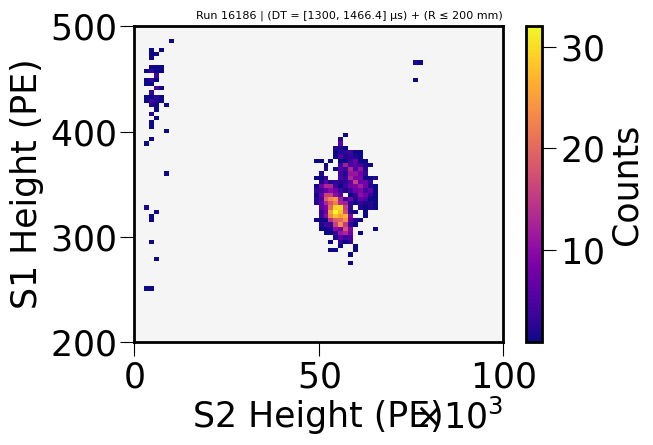

In [22]:
# Params
y_bins = np.linspace(200, 500, 75)
x_bins = np.linspace(0, 100e3, 75)

rad_lim = 200
dt_min = 1300

for key in SEL_DICT.keys():

    doro_df = SEL_DICT[key]['doro_df']
    cath_lim = EXTRA_INFO[key]['cath_lim']

    mask = (EXTRA_INFO[key]['alpha_mask']) & (doro_df['R'] <= rad_lim) & (doro_df['DT'] >= dt_min) & (doro_df['DT'] <= cath_lim)
    # if label == 'AV':
    #     mask = base_mask & (EXTRA_INFO[key]['AV_Z_mask'])
    #     ax = ax_left
    # else:
    #     mask = base_mask & (EXTRA_INFO[key]['cath_mask'])
    #     ax = ax_right

    if mask is not None:
        mask_df = doro_df[mask].copy()
    else:
        mask_df = doro_df.copy()

    # Variables    
    H1 = mask_df['S1h']
    H2 = mask_df['S2h']

    # 2D Histogram
    map2d, ex, ey = np.histogram2d(H2, H1, bins=[x_bins, y_bins])
    map2d         = np.ma.masked_where(map2d==0, map2d)

    # Plot
    plt.pcolormesh(ex, ey, map2d.T, cmap='plasma', shading='auto')
    plt.colorbar(label='Counts')
    plt.xlabel('S2 Height (PE)')
    plt.ylabel('S1 Height (PE)')
    plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
    plt.title(f'Run {key} | (DT = [{dt_min}, {cath_lim:.1f}] μs) + (R ≤ {rad_lim} mm)', loc='right', fontsize=8)

    plt.gca().set_facecolor("whitesmoke")
    plt.tight_layout()
    plt.show()

### $S2e$ vs $S1e$

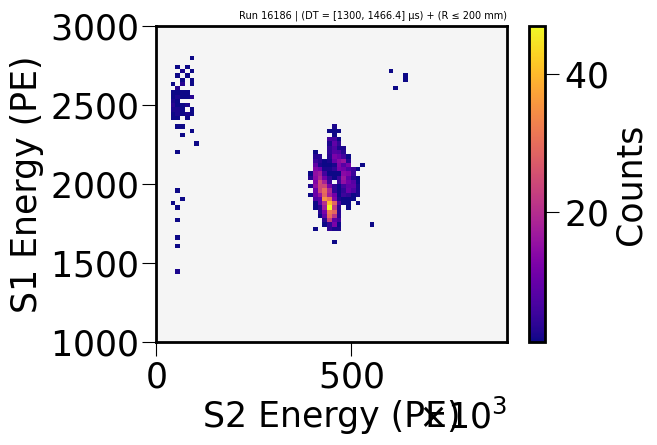

In [23]:
# Params
y_bins = np.linspace(1e3, 3e3, 75)
x_bins = np.linspace(0, 900e3, 75)

rad_lim = 200
dt_min = 1300

for key in SEL_DICT.keys():

    doro_df = SEL_DICT[key]['doro_df']
    cath_lim = EXTRA_INFO[key]['cath_lim']

    mask = (EXTRA_INFO[key]['alpha_mask']) & (doro_df['R'] <= rad_lim) & (doro_df['DT'] >= dt_min) & (doro_df['DT'] <= cath_lim)
    # if label == 'AV':
    #     mask = base_mask & (EXTRA_INFO[key]['AV_Z_mask'])
    #     ax = ax_left
    # else:
    #     mask = base_mask & (EXTRA_INFO[key]['cath_mask'])
    #     ax = ax_right

    if mask is not None:
        mask_df = doro_df[mask].copy()
    else:
        mask_df = doro_df.copy()

    # Variables    
    E1 = mask_df['S1e']
    E2 = mask_df['S2e']

    # 2D Histogram
    map2d, ex, ey = np.histogram2d(E2, E1, bins=[x_bins, y_bins])
    map2d         = np.ma.masked_where(map2d==0, map2d)

    # Plot
    plt.pcolormesh(ex, ey, map2d.T, cmap='plasma', shading='auto')
    plt.colorbar(label='Counts')
    plt.xlabel('S2 Energy (PE)')
    plt.ylabel('S1 Energy (PE)')
    plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
    plt.title(f'Run {key} | (DT = [{dt_min}, {cath_lim:.1f}] μs) + (R ≤ {rad_lim} mm)', loc='right', fontsize=7)

    plt.gca().set_facecolor("whitesmoke")
    plt.tight_layout()
    plt.show()

# Energy Corrections

In [37]:
# Store fits information
FIT_PARAMETERS = {key: {} for key in SEL_DICT.keys()}
FIT_PARAMETERS

{'16186': {}}

## Fits

### Light Collection

In [26]:
# # Global
# rad_lim = 200
# e1_lim  = 4e3

# # Fit region
# DT_down = 0;    DT_up = 1500
# # E1_down = 850;  E1_up = 2.8e3

# for key in SEL_DICT.keys():

#     doro_df = SEL_DICT[key]['doro_df']
#     run_id = int(key.split('_')[0])

#     # Masking
#     mask = EXTRA_INFO[key]['AV_Z_mask'] & (doro_df['R'] <= rad_lim) & (doro_df['S1e'] < e1_lim) #& (EXTRA_INFO[key]['w2_mask'])
#     if mask is not None:
#         mask_df = doro_df[mask].copy()

#     # Variables    
#     E1 = mask_df['S1e']
#     DT = mask_df['DT']

#     # 2D histogram
#     S1e_DT_map, ex, ey = crudo.pt.hist_2D(DT, E1, x_bins=50, y_bins=75)                       
#     S1e_DT_map         = np.ma.masked_where(S1e_DT_map==0, S1e_DT_map)

#     # ----- Linear Fit ----- #
#     DT_up = DT.max()
#     if   run_id == 16057:  E1_down = 0;  E1_up = 250
#     elif run_id == 14739:  E1_down = 650;  E1_up = 1.8e3
#     elif run_id == 14840:  E1_down = 650;  E1_up = 2e3
#     else:
#         E1_down = 850;    E1_up = 2.8e3
#     # Preliminary
#     DT_up = DT.max()

#     # Filter the data for the fit
#     fit_region_mask = (DT >= DT_down) & (DT <= DT_up) & \
#                       (E1 >= E1_down) & (E1 <= E1_up)
#     DT_fit = DT[fit_region_mask]
#     E1_fit = E1[fit_region_mask]

#     # Compute representative values for the fit
#     DT_centers, DT_errors, S1e_means, S1e_errors = crudo.ff.prefit_2D(DT_fit, E1_fit, bins=ex)
#     # Filter out points with zero error (bins with 1 event)
#     valid_points = S1e_errors > 0
#     DT_centers = DT_centers[valid_points];      DT_errors  = DT_errors[valid_points]
#     S1e_means  = S1e_means[valid_points];       S1e_errors = S1e_errors[valid_points]

#     # Definte the cost function + initial guess
#     least_squares = LeastSquares(DT_centers, S1e_means, S1e_errors, crudo.ff.linear_func)
#     init_guess = [10, S1e_means.min()]
#     # print(f'\nInitial guess: m = {init_guess[0]:.4f} PE/μs, b = {init_guess[1]:.4f} PE')

#     # Define the Minuit object
#     m = Minuit(least_squares, *init_guess)

#     # Minimization process of the cost function and error estimation
#     m.migrad()
#     m.hesse()

#     # Results
#     popt = m.values;  perr = m.errors
#     print(f'Fit: m = ({popt[0]:.2f} ± {perr[0]:.2f}) PE/μs, b = ({popt[1]:.2f} ± {perr[1]:.2f}) PE')    
#     FIT_PARAMETERS[key]["S1e"] = {"m_CV": popt[0], "m_err": perr[0], "b_CV": popt[1], "b_err": perr[1]}

#     # Reduced chi-square
#     chi2 = m.fval
#     ndof = len(DT_centers) - m.nfit
#     print(f"     χ² / ndof = {chi2 / ndof:.2f}")

#     # ----- Plotting ----- #
#     plt.figure(figsize=(8, 6))
#     # Data
#     plt.pcolormesh(ex, ey, S1e_DT_map.T, cmap='plasma', shading='auto')    
#     cbar = plt.colorbar(label='Counts', shrink=1.0)
#     # cbar.formatter.set_powerlimits((-3, -3))

#     # Fit
#     fit_y = crudo.ff.linear_func(DT_centers, *popt)
#     plt.errorbar(DT_centers, S1e_means, xerr=DT_errors, yerr=S1e_errors, fmt='o', c='lightgray', ecolor='lightgray', lw=1.0, markersize=3)
#     plt.plot(DT_centers, fit_y, c='black', ls='--', lw=1.5, zorder=3)
#     plt.axhline(y=E1_up, c='red', ls='--')
#     plt.axhline(y=E1_down, c='red', ls='--')

#     # ----- Styling ----- #
#     plt.xlabel('$\Delta$T ($\mu$s)')
#     plt.ylabel('Unc. S1 Energy (PE)')
#     plt.xlim(ex[0], ex[-1])
#     # plt.ylim(0, e1_lim)
#     plt.xticks(np.arange(0, DT.max(), 300))
#     plt.title(f'Run {key} | AV + (R ≤ {rad_lim} mm)', fontsize=12, loc='right')

#     plt.gca().set_facecolor("whitesmoke")
#     plt.tight_layout()
#     plt.show() 

Fit: m = (0.12 ± 0.00) PE/μs, b = (172.33 ± 0.40) PE
     χ² / ndof = 3.95


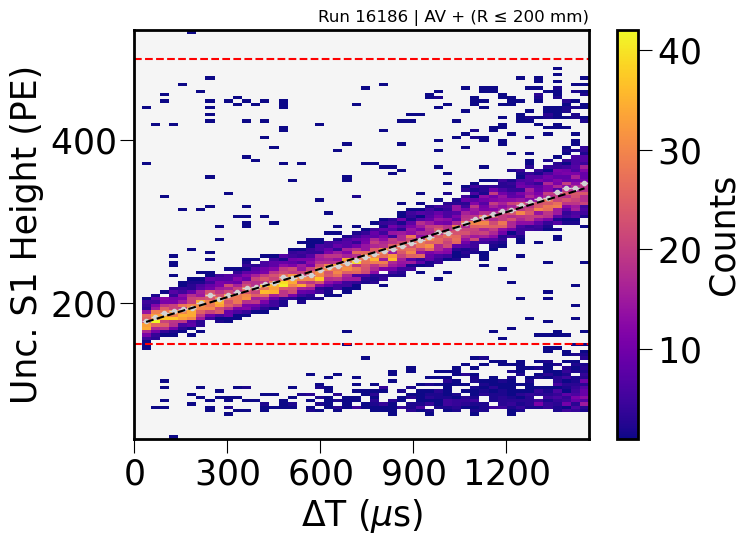

In [38]:
# Params
rad_lim = 200
DT_down = 0
DT_up   = 1500

for key in SEL_DICT.keys():

    doro_df = SEL_DICT[key]['doro_df']
    run_id = int(key.split('_')[0])

    # Masking
    mask = EXTRA_INFO[key]['AV_Z_mask'] & (doro_df['R'] <= rad_lim)
    if mask is not None:
        mask_df = doro_df[mask].copy()
    else:
        mask_df = doro_df.copy()

    # Variables    
    H1 = mask_df['S1h']
    DT = mask_df['DT']

    # 2D histogram
    map_2d, ex, ey = crudo.pt.hist_2D(DT, H1, x_bins=50, y_bins=125)
    map_2d         = np.ma.masked_where(map_2d==0, map_2d)

    # ----- Linear Fit ----- #
    DT_up = DT.max()
    if run_id == 16057:  H1_down = 0;  H1_up = 250
    else:
        H1_down = 150;    H1_up = 500

    # Filter the data for the fit
    fit_region_mask = (DT >= DT_down) & (DT <= DT_up) & \
                      (H1 >= H1_down) & (H1 <= H1_up)
    DT_fit = DT[fit_region_mask]
    H1_fit = H1[fit_region_mask]

    # Compute representative values for the fit
    x_values, x_errors, y_values, y_errors = crudo.ff.prefit_2D(DT_fit, H1_fit, bins=ex)
    # Filter out points with zero error (bins with 1 event)
    valid_points = y_errors > 0
    x_values = x_values[valid_points];      x_errors  = x_errors[valid_points]
    y_values = y_values[valid_points];      y_errors = y_errors[valid_points]

    # Definte the cost function + initial guess
    least_squares = LeastSquares(x_values, y_values, y_errors, crudo.ff.linear_func)
    init_guess = [10, y_values.min()]
    # print(f'\nInitial guess: m = {init_guess[0]:.4f} PE/μs, b = {init_guess[1]:.4f} PE')

    # Define the Minuit object
    m = Minuit(least_squares, *init_guess)

    # Minimization process of the cost function and error estimation
    m.migrad()
    m.hesse()

    # Results
    popt = m.values;  perr = m.errors
    print(f'Fit: m = ({popt[0]:.2f} ± {perr[0]:.2f}) PE/μs, b = ({popt[1]:.2f} ± {perr[1]:.2f}) PE')    
    FIT_PARAMETERS[key]["S1"] = {"m_CV": popt[0], "m_err": perr[0], "b_CV": popt[1], "b_err": perr[1]}

    # Reduced chi-square
    chi2 = m.fval
    ndof = len(x_values) - m.nfit
    print(f"     χ² / ndof = {chi2 / ndof:.2f}")

    # ----- Plotting ----- #
    plt.figure(figsize=(8, 6))
    # Data
    plt.pcolormesh(ex, ey, map_2d.T, cmap='plasma', shading='auto')    
    cbar = plt.colorbar(label='Counts', shrink=1.0)
    # cbar.formatter.set_powerlimits((-3, -3))

    # Fit
    fit_y = crudo.ff.linear_func(x_values, *popt)
    plt.errorbar(x_values, y_values, xerr=x_errors, yerr=y_errors, fmt='o', c='lightgray', ecolor='lightgray', lw=1.0, markersize=3)
    plt.plot(x_values, fit_y, c='black', ls='--', lw=1.5, zorder=3)
    plt.axhline(y=H1_up, c='red', ls='--', lw=1.5)
    plt.axhline(y=H1_down, c='red', ls='--', lw=1.5)

    # ----- Styling ----- #
    plt.xlabel('$\Delta$T ($\mu$s)')
    plt.ylabel('Unc. S1 Height (PE)')
    plt.xlim(ex[0], ex[-1])
    # plt.ylim(0, H1_lim)
    plt.xticks(np.arange(0, DT.max(), 300))
    plt.title(f'Run {key} | AV + (R ≤ {rad_lim} mm)', fontsize=12, loc='right')

    plt.gca().set_facecolor("whitesmoke")
    plt.tight_layout()
    plt.show() 

### Lifetime

Fit: N0 = (462624.66 ± 392.13) PE, τ = (21.82 ± 0.47) ms
     χ² / ndof = 2.20


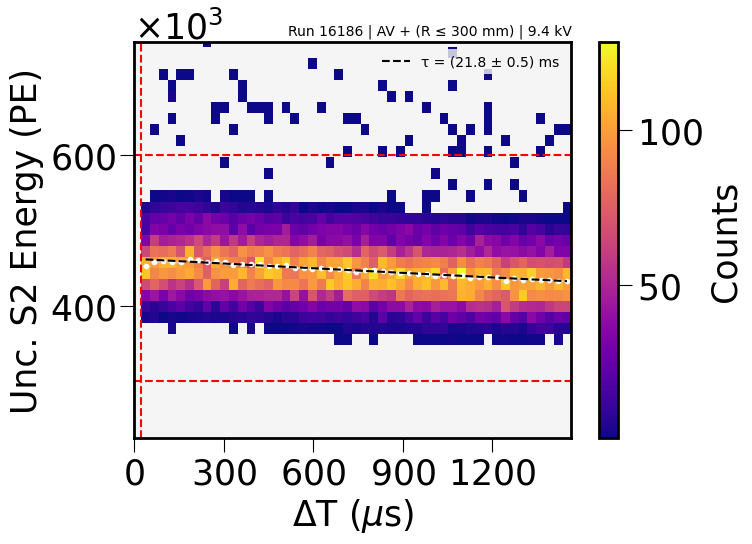

In [39]:
# Global
rad_lim = 300

# Use exponential decay function with b = 0
def exp_bfixed(x, N0, tau):
    return crudo.ff.exponential_decay(x, N0, tau, 0)

for key in SEL_DICT.keys():

    doro_df = SEL_DICT[key]['doro_df']
    run_id = int(key.split('_')[0])
    gate_volt = RUNS_INFO_DF.loc[RUNS_INFO_DF['run_number'] == run_id, 'gate_voltage'].values[0] / 1e3

    # Masking
    mask = EXTRA_INFO[key]['alpha_mask'] & EXTRA_INFO[key]['AV_Z_mask'] & (doro_df['R'] <= rad_lim)
    if mask is not None:
        mask_df = doro_df[mask].copy()
    else:
        mask_df = doro_df.copy()
        
    # Variables    
    E2 = mask_df['S2e']
    DT = mask_df['DT']

    # 2D histogram: normalized by corrected DAQ data taking time
    map_2d, ex, ey = crudo.pt.hist_2D(DT, E2, x_bins=50, y_bins=50)                           
    map_2d         = np.ma.masked_where(map_2d==0, map_2d)
    
    # ---- Exponential Fit ----- #
    DT_down = DT.min();    DT_up = DT.max()
    if   run_id == 14739:  E2_down = 775e3;  E2_up = 850e3
    elif run_id == 14840:  E2_down = 850e3;  E2_up = 950e3;  DT_down = 300
    elif run_id == 16057:  E2_down = 15e3 ;  E2_up = 30e3
    elif run_id == 16105:  E2_down = 500e3;  E2_up = 800e3
    elif run_id == 16114:  E2_down = 600e3;  E2_up = 1100e3  
    elif run_id == 16116:  E2_down = 600e3;  E2_up = 1100e3;  DT_down = 300
    else:
        E2_down = 300e3;    E2_up = 600e3
    
    # Filter the data for the fit
    fit_region_mask = (DT >= DT_down) & (DT <= DT_up) & \
                      (E2 >= E2_down) & (E2 <= E2_up)
    DT_fit = DT[fit_region_mask]
    E2_fit = E2[fit_region_mask]

    # Compute representative values for the fit
    x_values, x_errors, y_values, y_errors = crudo.ff.prefit_2D(DT_fit, E2_fit, bins=ex)
    # Filter out points with zero error (bins with 1 event)
    valid_points = y_errors > 0
    x_values = x_values[valid_points];      x_errors  = x_errors[valid_points]
    y_values  = y_values[valid_points];     y_errors = y_errors[valid_points]

    # Definte the cost function + initial guess
    least_squares = LeastSquares(x_values, y_values, y_errors, exp_bfixed)
    init_guess = [y_values.max(), (x_values.max() - x_values.min()) / 2]
    # print(f'\nInitial guess: N0 = {init_guess[0]:.4f} PE, tau = {init_guess[1]:.4f} μs')

    # Define the Minuit object
    m = Minuit(least_squares, *init_guess)

    # Minimization process of the cost function and error estimation
    m.migrad()
    m.hesse()

    # Results
    popt = m.values;  perr = m.errors
    print(f'Fit: N0 = ({popt[0]:.2f} ± {perr[0]:.2f}) PE, τ = ({popt[1] / 1e3:.2f} ± {perr[1] / 1e3:.2f}) ms')
    FIT_PARAMETERS[key]["S2"] = {"N0_CV": popt[0], "N0_err": perr[0], "tau_CV": popt[1], "tau_err": perr[1]}
    
    # Reduced chi-square
    chi2 = m.fval
    ndof = len(x_values) - m.nfit
    print(f"     χ² / ndof = {chi2 / ndof:.2f}")

    # ----- Plotting ----- #
    plt.figure(figsize=(8, 6))
    # Data
    plt.pcolormesh(ex, ey, map_2d.T, cmap='plasma', shading='auto')
    cbar = plt.colorbar(label='Counts', shrink=1.0)
    # cbar.formatter.set_powerlimits((-3, -3))

    # Fit
    fit_y = exp_bfixed(x_values, *popt)
    plt.errorbar(x_values, y_values, xerr=x_errors, yerr=y_errors, fmt='o', c='white', ecolor='lightgray', lw=1.0, markersize=3)
    plt.plot(x_values, fit_y, c='black', ls='--', lw=1.5, zorder=3, label=f'τ = ({popt[1] / 1e3:.1f} ± {perr[1] / 1e3:.1f}) ms')
    plt.axvline(x=DT_down, c='red', ls='--', lw=1.5)
    plt.axhline(y=E2_down, c='red', ls='--', lw=1.5)
    plt.axhline(y=E2_up, c='red', ls='--', lw=1.5)

    # ----- Styling ----- #
    plt.xlabel('$\Delta$T ($\mu$s)')
    plt.ylabel('Unc. S2 Energy (PE)')
    plt.xlim(0, ex[-1])
    plt.ylim(0.75*E2_down, 1.25*E2_up)    
    plt.xticks(np.arange(0, DT.max(), 300))
    plt.ticklabel_format(axis='y', style='sci', scilimits=(3, 3))
    plt.title(f'Run {key} | AV + (R ≤ {rad_lim} mm) | {gate_volt:.1f} kV', fontsize=10, loc='right')
    plt.legend(loc='upper right', facecolor='whitesmoke', fontsize=10)

    plt.gca().set_facecolor("whitesmoke")
    plt.tight_layout()
    # plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/images/LT_run_{key}.pdf')
    plt.show() 

## Apply Corrections

In [79]:
# # Global
# n_bins = 35

# # Reference DataFrame for energy map generation
# ref_key = list(FIT_PARAMETERS.keys())[0] 
# ref_df = SEL_DICT[ref_key]['doro_df'].copy()
# CV_fit = [FIT_PARAMETERS[ref_key]['S1e']['m_CV'],  FIT_PARAMETERS[ref_key]['S1e']['b_CV']]
# LT_fit = [FIT_PARAMETERS[ref_key]['S2e']['N0_CV'], FIT_PARAMETERS[ref_key]['S2e']['tau_CV']]

# print(f"Generating energy map of reference...\nThank you run {ref_key} for your stats")

# ref_df = crudo.ef.correct_S2e_LT(ref_df, LT_fit, output_column='S2e_corr_LT')   # S2 energy by lifetime

# # Variables
# X_ref  = ref_df['X']
# Y_ref  = ref_df['Y']
# E2_ref = ref_df['S2e_corr_LT']
# mask = EXTRA_INFO[ref_key]['AV_Z_mask']

# # Generate the energy map normalized to the center
# ref_energy_map, x_edges, y_edges = crudo.ef.pt.mapping(X_ref[mask], Y_ref[mask], wei=E2_ref[mask], 
#                                                        bin_scale=4, max_limit=crudo.pt.N100_rad, norm=True)

In [40]:
FIT_PARAMETERS

{'16186': {'S1': {'m_CV': 0.11602484405521807,
   'm_err': 0.0005234533514452658,
   'b_CV': 172.32523411002148,
   'b_err': 0.3951367929185653},
  'S2': {'N0_CV': 462624.657549619,
   'N0_err': 392.1288508254712,
   'tau_CV': 21824.047643408252,
   'tau_err': 473.2537461598491}}}

In [41]:
for key in SEL_DICT.keys():

    print(f"--- Run {key} ---")
    doro_df  = SEL_DICT[key]['doro_df']
    cath_lim = EXTRA_INFO[key]['cath_lim']

    # Fit parameters
    CV_fit = [FIT_PARAMETERS[key]['S1']['m_CV'],  FIT_PARAMETERS[key]['S1']['b_CV']]
    LT_fit = [FIT_PARAMETERS[key]['S2']['N0_CV'], FIT_PARAMETERS[key]['S2']['tau_CV']]
        
    # Apply corrections
    doro_df = crudo.ef.correct_S1e   (doro_df, CV_fit, cath_lim, input_column='S1h', output_column='S1h_corr')      # S1 energy
    doro_df = crudo.ef.correct_S2e_LT(doro_df, LT_fit, output_column='S2e_corr_LT')   # S2 energy by lifetime
    doro_df = crudo.ef.correct_S2e_map(doro_df, cath_lim)                             # S2 energy by radial map
    
    # Apply S2 energy correction by fixed geometric map
    # doro_df = crudo.ef.correct_S2e_map_fixed(doro_df, ref_energy_map, x_edges, y_edges)

--- Run 16186 ---


## Control Plots

#### $S1e$ - Active Volume

Run 16186:


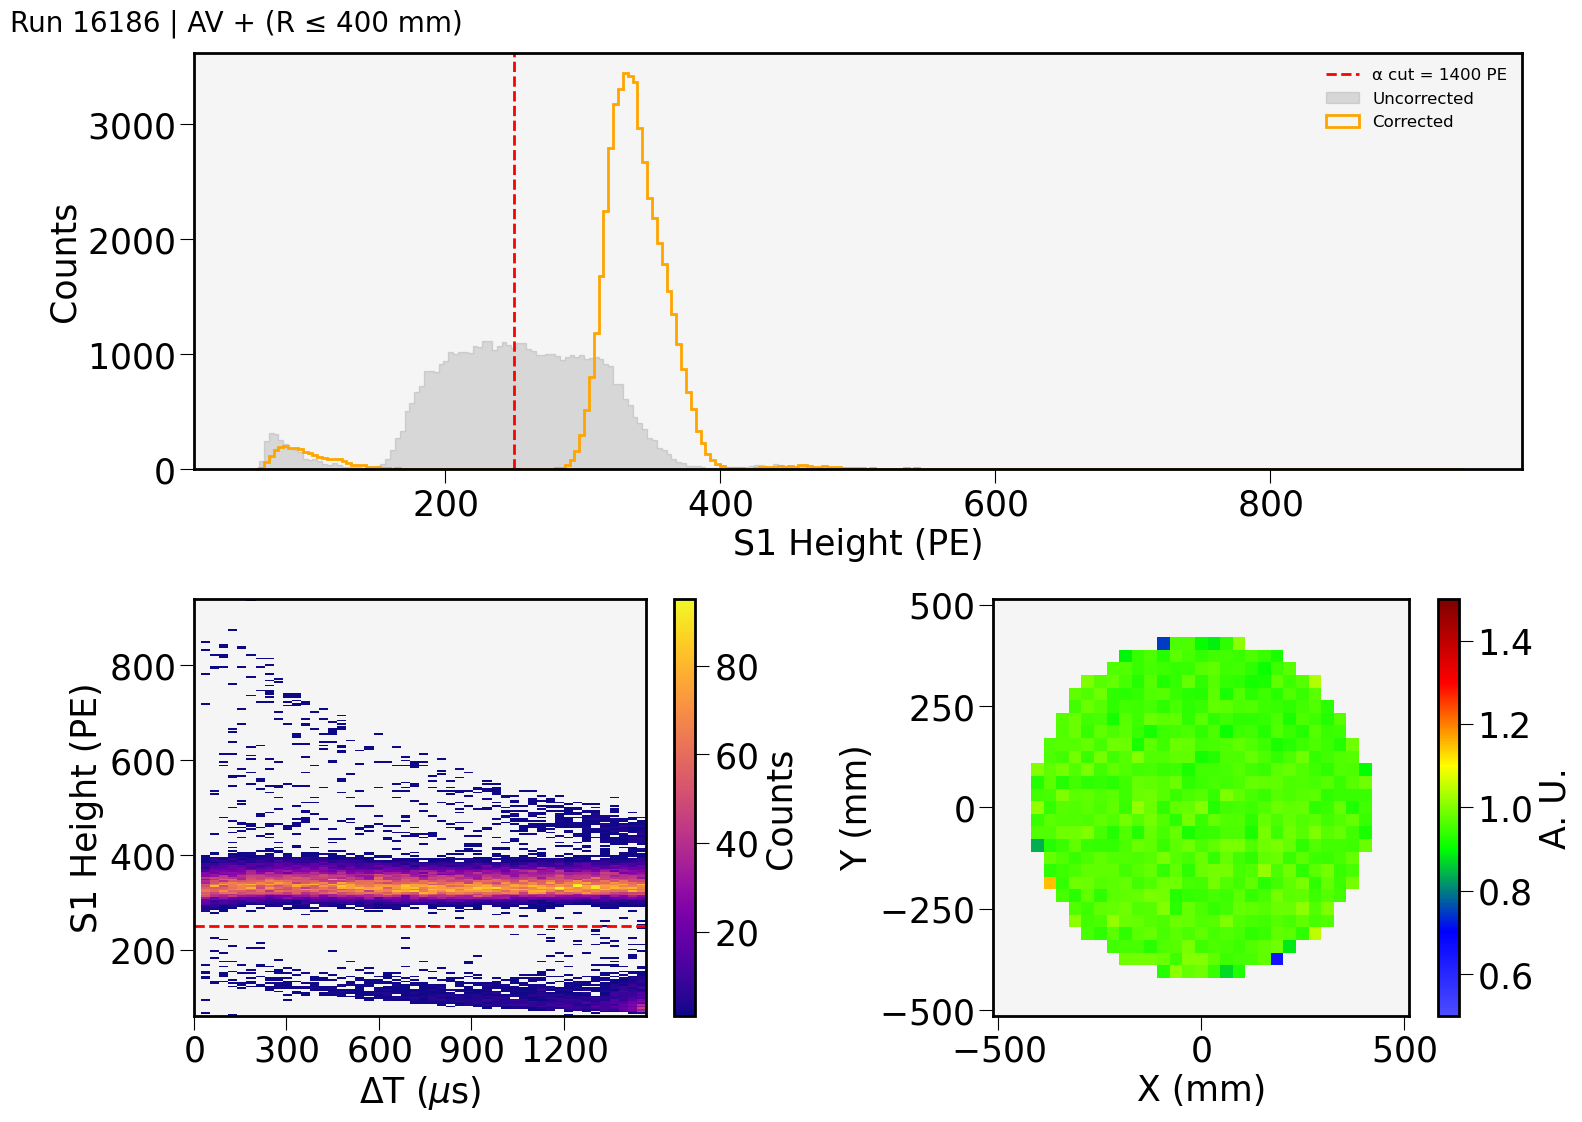

In [49]:
# Params
rad_lim = 400

for key in SEL_DICT.keys():

    print(f"Run {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Masking
    mask = EXTRA_INFO[key]['AV_Z_mask'] & (doro_df['R'] <= rad_lim) #& (EXTRA_INFO[key]['w2_mask'])
    if mask is not None:
        mask_df = doro_df[mask].copy()
    else:
        mask_df = doro_df.copy()
    
    # Variables
    X = mask_df['X']
    Y = mask_df['Y']
    DT  = mask_df['DT']
    H1  = mask_df['S1h']
    H1c = mask_df['S1h_corr']

    # 2D histogram: normalized by corrected DAQ data taking time
    map_2d, ex, ey = crudo.pt.hist_2D(DT, H1c, x_bins=50, y_bins=250)                        
    map_2d = np.ma.masked_where(map_2d == 0, map_2d)

    # Energy map
    s1e_map, ex_map, ey_map = crudo.pt.mapping(X, Y, wei=H1c, bin_scale=2, max_limit=crudo.pt.N100_rad, norm=True)
    s1e_map = np.ma.masked_where(s1e_map==0, s1e_map)

    # ----- Plotting ----- #
    fig = plt.figure(figsize=(16, 12))
    gs = GridSpec(2, 2, figure=fig)

    ax_top = fig.add_subplot(gs[0, :])
    ax_bottom_left = fig.add_subplot(gs[1, 0])
    ax_bottom_right = fig.add_subplot(gs[1, 1])

    # Upper left
    ax_top.hist(H1, bins=ey, histtype='stepfilled', lw=1.0, color='grey', alpha=0.25, ec='grey', label='Uncorrected')
    ax_top.hist(H1c, bins=ey, histtype='step', lw=2.0, color='orange', alpha=1.0, ec='orange', label='Corrected')
    ax_top.set_xlabel('S1 Height (PE)')
    ax_top.set_ylabel('Counts')
    # ax_top.set_xlim(0, H1_lim)
    # ax_top.set_yscale('log')
    ax_top.axvline(x=250, c='red', ls='--', lw=2.0, label=f'α cut = {ALPHA_CUT} PE')
    ax_top.legend(loc='upper right', fontsize=12, facecolor='none')
    ax_top.set_facecolor('whitesmoke')

    # Lower left
    pcm = ax_bottom_left.pcolormesh(ex, ey, map_2d.T, cmap='plasma', shading='auto')
    cbar = fig.colorbar(pcm, ax=ax_bottom_left, label='Counts')
    ax_bottom_left.set_xlabel('$\Delta$T ($\mu$s)')
    ax_bottom_left.set_ylabel('S1 Height (PE)')
    ax_bottom_left.set_xlim(ex[0], ex[-1])
    # ax_bottom_left.set_ylim(0, H1_lim)
    ax_bottom_left.set_xticks(np.arange(0, DT.max(), 300))
    ax_bottom_left.axhline(y=250, c='red', ls='--', lw=2.0)
    ax_bottom_left.set_facecolor('whitesmoke')

    # Lower right
    pcm = ax_bottom_right.pcolormesh(ex_map, ey_map, s1e_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.5, vmax=1.5)
    cbar = fig.colorbar(pcm, ax=ax_bottom_right, label='A. U.')
    ax_bottom_right.set_xlabel('X (mm)')
    ax_bottom_right.set_ylabel('Y (mm)')
    ax_bottom_right.set_aspect('equal', adjustable='box')
    ax_bottom_right.set_facecolor('whitesmoke')


    # Single title for the figure
    fig.suptitle(f'Run {key} | AV + (R ≤ {rad_lim} mm)', fontsize=20, x=0, y=0.95, ha='left')

    plt.tight_layout()
    plt.show()

#### $S1e$ - Cathode

Run 16186:


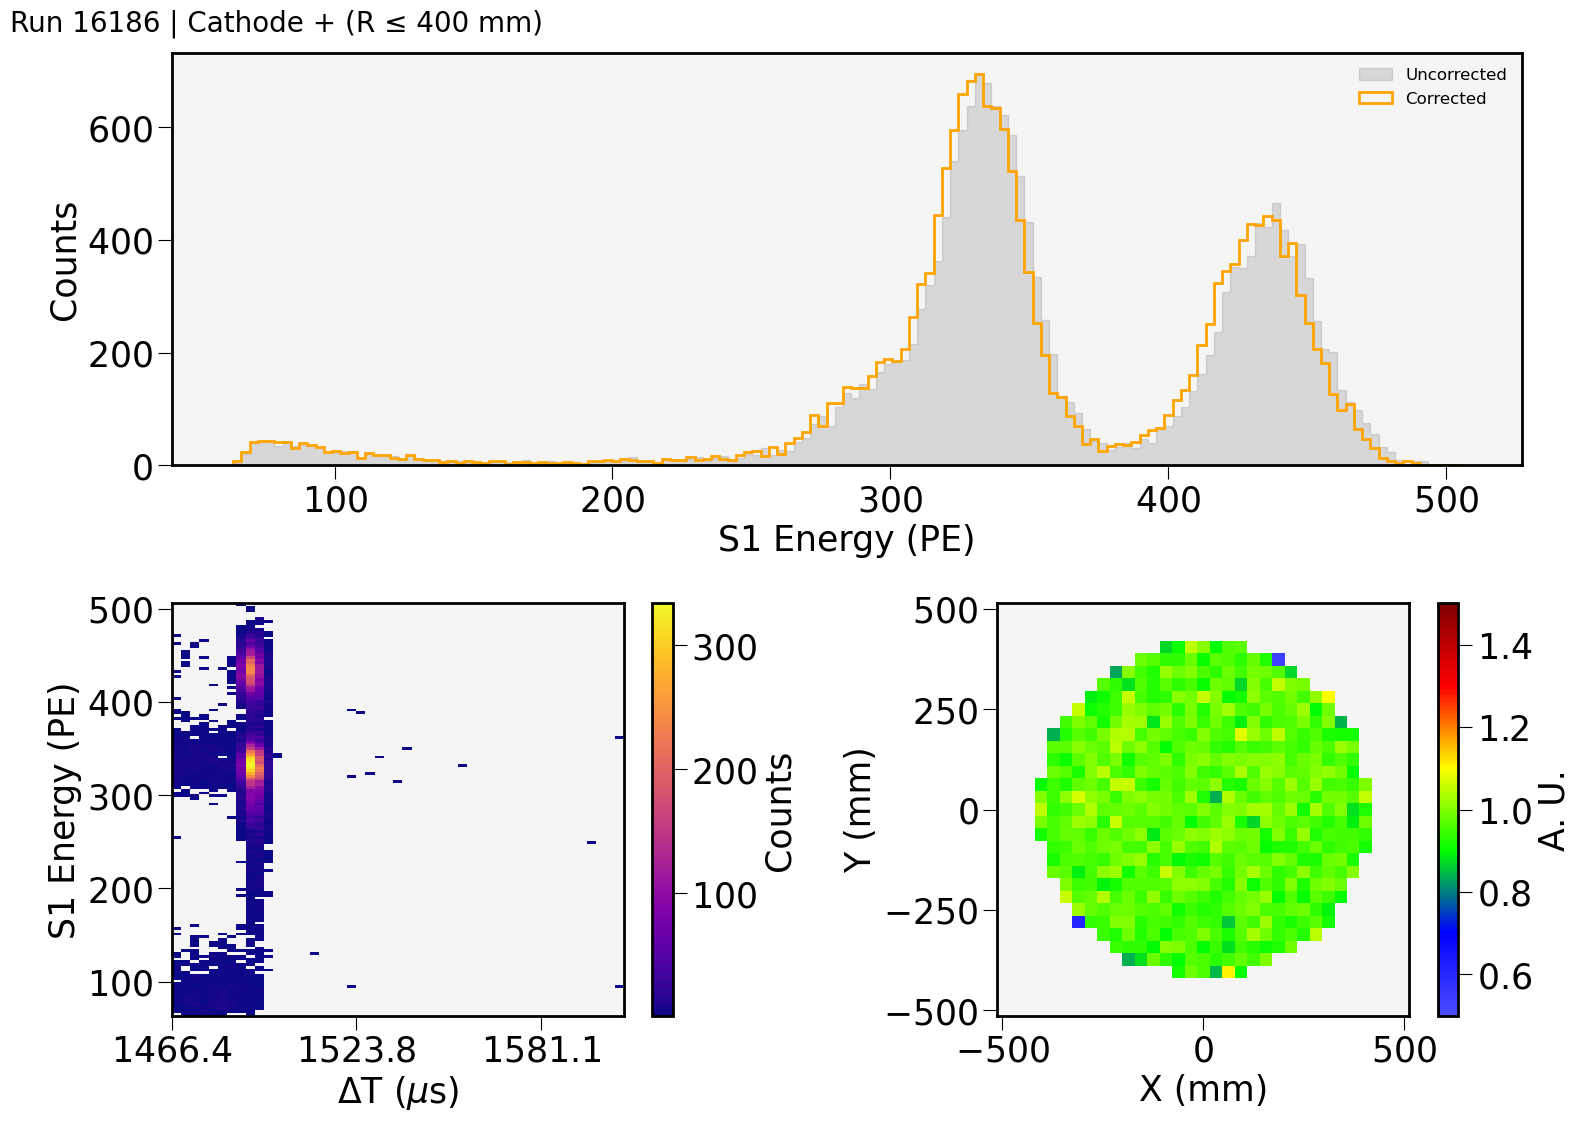

In [52]:
# Global
rad_lim = 400

for key in SEL_DICT.keys():

    print(f"Run {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Masking
    mask =  EXTRA_INFO[key]['cath_mask'] & (doro_df['R'] <= rad_lim)
    if mask is not None:
        mask_df = doro_df[mask].copy()
    else:
        mask_df = doro_df.copy()
    
    # Variables
    X = mask_df['X']
    Y = mask_df['Y']
    DT  = mask_df['DT']
    H1  = mask_df['S1h']
    H1c = mask_df['S1h_corr']

    # 2D histogram: normalized by corrected DAQ data taking time
    map_2d, ex, ey = crudo.pt.hist_2D(DT, H1c, x_bins=50, y_bins=150)                        
    map_2d = np.ma.masked_where(map_2d == 0, map_2d)

    # Energy map
    s1e_map, ex_map, ey_map = crudo.pt.mapping(X, Y, wei=H1c, bin_scale=2, max_limit=crudo.pt.N100_rad, norm=True)
    s1e_map = np.ma.masked_where(s1e_map==0, s1e_map)

    # ----- Plotting ----- #
    fig = plt.figure(figsize=(16, 12))
    gs = GridSpec(2, 2, figure=fig)

    ax_top = fig.add_subplot(gs[0, :])
    ax_bottom_left = fig.add_subplot(gs[1, 0])
    ax_bottom_right = fig.add_subplot(gs[1, 1])

    # Upper left
    ax_top.hist(H1, bins=ey, histtype='stepfilled', lw=1.0, color='grey', alpha=0.25, ec='grey', label='Uncorrected')
    ax_top.hist(H1c, bins=ey, histtype='step', lw=2.0, color='orange', alpha=1.0, ec='orange', label='Corrected')
    ax_top.set_xlabel('S1 Energy (PE)')
    ax_top.set_ylabel('Counts')
    # ax_top.set_xlim(0, H1_lim)
    # ax_top.set_yscale('log')
    # ax_top.axvline(x=ALPHA_CUT, c='red', ls='--', lw=2.0, label=f'α cut = {ALPHA_CUT} PE')
    ax_top.legend(loc='upper right', fontsize=12, facecolor='none')
    ax_top.set_facecolor('whitesmoke')

    # Lower left
    pcm = ax_bottom_left.pcolormesh(ex, ey, map_2d.T, cmap='plasma', shading='auto')
    cbar = fig.colorbar(pcm, ax=ax_bottom_left, label='Counts')
    ax_bottom_left.set_xlabel('$\Delta$T ($\mu$s)')
    ax_bottom_left.set_ylabel('S1 Energy (PE)')
    ax_bottom_left.set_xlim(ex[0], ex[-1])
    # ax_bottom_left.set_ylim(0, H1_lim)
    ax_bottom_left.set_xticks(ex[::20])
    # ax_bottom_left.axhline(y=ALPHA_CUT, c='red', ls='--', lw=2.0)
    ax_bottom_left.set_facecolor('whitesmoke')

    # Lower right
    pcm = ax_bottom_right.pcolormesh(ex_map, ey_map, s1e_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.5, vmax=1.5)
    cbar = fig.colorbar(pcm, ax=ax_bottom_right, label='A. U.')
    ax_bottom_right.set_xlabel('X (mm)')
    ax_bottom_right.set_ylabel('Y (mm)')
    ax_bottom_right.set_aspect('equal', adjustable='box')
    ax_bottom_right.set_facecolor('whitesmoke')


    # Single title for the figure
    fig.suptitle(f'Run {key} | Cathode + (R ≤ {rad_lim} mm)', fontsize=20, x=0, y=0.95, ha='left')

    plt.tight_layout()
    plt.show()

#### $S2e$ - Active Volume

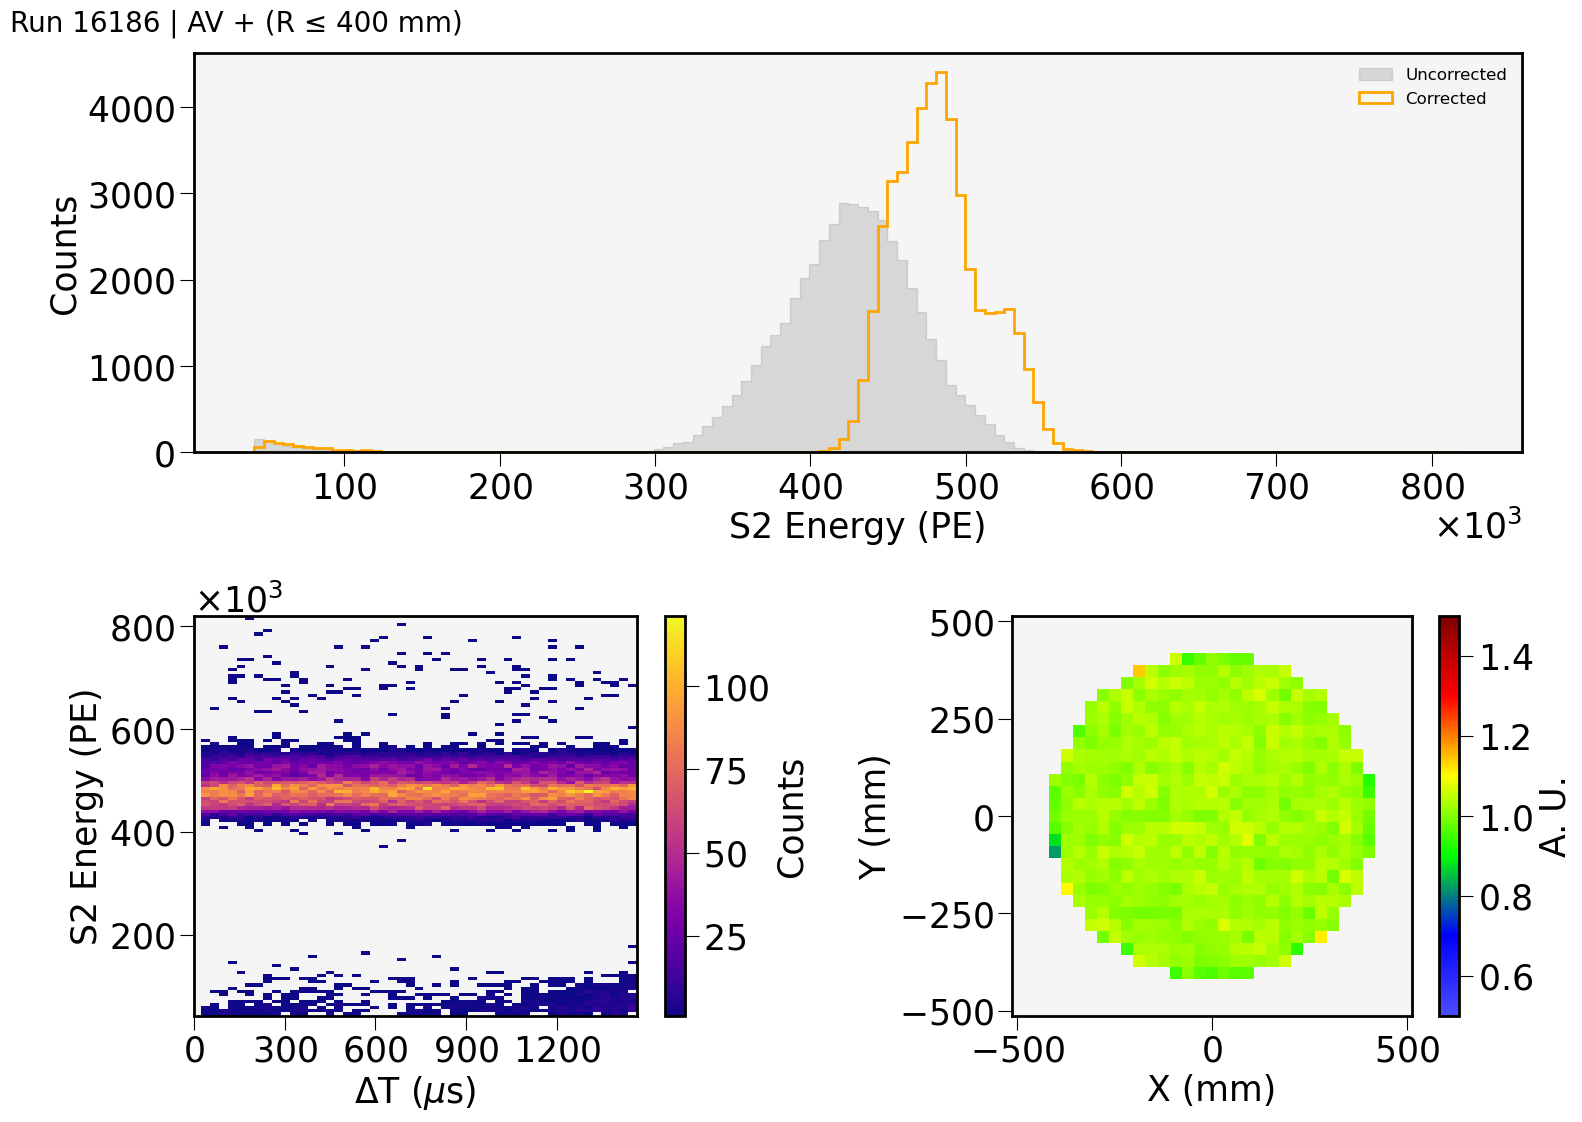

In [56]:
# Global
r_lims = [400]
# r_lims = [100, 200, 300, 400, 500]

for key in SEL_DICT.keys():

    doro_df = SEL_DICT[key]['doro_df']
    run_id = int(key.split('_')[0])

    if run_id == 14739: E2_min = 600e3;  E2_max = 1100e3
    elif run_id == 16057: E2_min = 15e3;   E2_max = 30e3
    elif run_id == 16123: E2_min = 300e3;  E2_max = 700e3

    for rad_lim in r_lims:

        # Masking
        mask =  EXTRA_INFO[key]['alpha_mask'] & EXTRA_INFO[key]['AV_Z_mask'] & (doro_df['R'] <= rad_lim)#& (EXTRA_INFO[key]['w2_mask'])
        if mask is not None:
            mask_df = doro_df[mask].copy()
        else:
            mask_df = doro_df.copy()
        
        # Variables
        X = mask_df['X']
        Y = mask_df['Y']
        DT  = mask_df['DT']
        E2  = mask_df['S2e']
        E2c = mask_df['S2e_corr']

        # 2D histogram: normalized by corrected DAQ data taking time
        S2e_DT_map, ex, ey = crudo.pt.hist_2D(DT, E2c, x_bins=50, y_bins=125)                        
        S2e_DT_map = np.ma.masked_where(S2e_DT_map == 0, S2e_DT_map)

        # Energy map
        s2e_map, ex_map, ey_map = crudo.pt.mapping(X, Y, wei=E2c, bin_scale=2, max_limit=crudo.pt.N100_rad, norm=True)
        s2e_map = np.ma.masked_where(s2e_map==0, s2e_map)

        # ----- Plotting ----- #
        fig = plt.figure(figsize=(16, 12))
        gs = GridSpec(2, 2, figure=fig)

        ax_top = fig.add_subplot(gs[0, :])
        ax_bottom_left = fig.add_subplot(gs[1, 0])
        ax_bottom_right = fig.add_subplot(gs[1, 1])

        # Upper left
        ax_top.hist(E2, bins=ey, histtype='stepfilled', lw=1.0, color='grey', alpha=0.25, ec='grey', label='Uncorrected')
        ax_top.hist(E2c, bins=ey, histtype='step', lw=2.0, color='orange', alpha=1.0, ec='orange', label='Corrected')
        ax_top.set_xlabel('S2 Energy (PE)')
        ax_top.set_ylabel('Counts')
        # ax_top.set_xlim(E2_min, E2_max)
        # ax_top.set_yscale('log')
        ax_top.ticklabel_format(axis='x', style='sci', scilimits=(3,3))
        ax_top.legend(loc='upper right', fontsize=12, facecolor='none')
        ax_top.set_facecolor('whitesmoke')

        # Lower left
        pcm = ax_bottom_left.pcolormesh(ex, ey, S2e_DT_map.T, cmap='plasma', shading='auto')
        cbar = fig.colorbar(pcm, ax=ax_bottom_left, label='Counts')
        ax_bottom_left.set_xlabel('$\Delta$T ($\mu$s)')
        ax_bottom_left.set_ylabel('S2 Energy (PE)')
        ax_bottom_left.set_xlim(ex[0], ex[-1])
        # ax_bottom_left.set_ylim(E2_min, E2_max)
        ax_bottom_left.set_xticks(np.arange(0, DT.max(), 300))
        ax_bottom_left.ticklabel_format(axis='y', style='sci', scilimits=(3,3))
        ax_bottom_left.set_facecolor('whitesmoke')

        # Lower right
        pcm = ax_bottom_right.pcolormesh(ex_map, ey_map, s2e_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.5, vmax=1.5)
        cbar = fig.colorbar(pcm, ax=ax_bottom_right, label='A. U.')
        ax_bottom_right.set_xlabel('X (mm)')
        ax_bottom_right.set_ylabel('Y (mm)')
        ax_bottom_right.set_aspect('equal', adjustable='box')
        ax_bottom_right.set_facecolor('whitesmoke')

        # Single title for the figure
        fig.suptitle(f'Run {key} | AV + (R ≤ {rad_lim} mm)', fontsize=20, x=0, y=0.95, ha='left')

        plt.tight_layout()
        # plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/images/S2e_corr_run_{key}_AV_R{rad_lim}.pdf')
        plt.show()

-----
Sometimes plots

Run 16123:


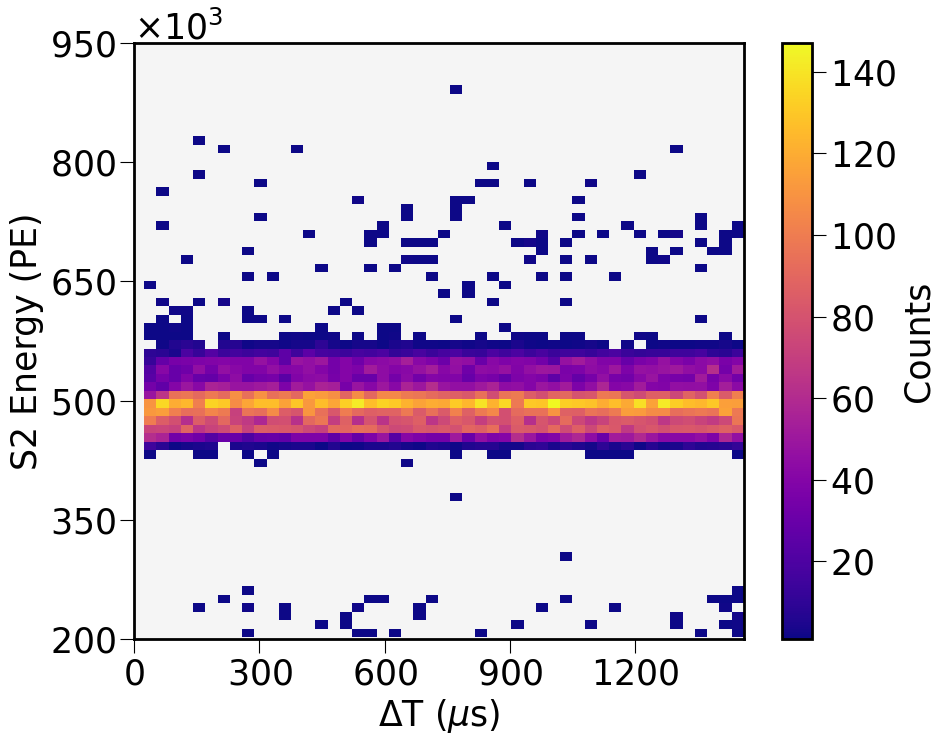

In [ ]:
# # Global
# r_lims = [300]
# # r_lims = [100, 200, 300, 400, 500]

# for key in SEL_DICT.keys():

#     print(f"Run {key}:")
#     doro_df = SEL_DICT[key]['doro_df']
#     run_id = int(key.split('_')[0])

#     if run_id == 14739: E2_min = 600e3;     E2_max = 1100e3
#     elif run_id == 16057: E2_min = 15e3;      E2_max = 35e3
#     elif run_id == 16123: E2_min = 200e3;   E2_max = 950e3

#     for rad_lim in r_lims:

#         # Variables
#         X = doro_df['X']
#         Y = doro_df['Y']
#         R = np.sqrt(X**2 + Y**2)
#         W1 = doro_df['S1w']
#         DT = doro_df['DT']
#         E1c = doro_df['S1e_corr']
#         E2 = doro_df['S2e']
#         E2c = doro_df['S2e_corr']

#         # Masking
#         mask = EXTRA_INFO[key]['AV_Z_mask'] & (R <= rad_lim) & (E2 >= E2_min) & (E2 <= E2_max)#& (E1c >= ALPHA_CUT)
#         if mask is not None:
#             X = X[mask]
#             Y = Y[mask]
#             R = R[mask]
#             DT = DT[mask]
#             E2 = E2[mask]
#             E2c = E2c[mask]

#         # 2D histogram: normalized by corrected DAQ data taking time
#         S2e_DT_map, ex, ey = crudo.pt.hist_2D(DT, E2c, x_bins=50, y_bins=75)
#         S2e_DT_map = np.ma.masked_where(S2e_DT_map == 0, S2e_DT_map)

#         # ----- Plotting ----- #
#         fig, ax = plt.subplots(figsize=(10, 8))

#         # Lower left
#         pcm = ax.pcolormesh(ex, ey, S2e_DT_map.T, cmap='plasma', shading='auto')
#         cbar = fig.colorbar(pcm, ax=ax, label='Counts')
#         ax.set_xlabel('$\Delta$T ($\mu$s)')
#         ax.set_ylabel('S2 Energy (PE)')
#         ax.set_xlim(ex[0], ex[-1])
#         ax.set_ylim(E2_min, E2_max)
#         ax.set_xticks(np.arange(0, DT.max(), 300))
#         ax.set_yticks(np.arange(E2_min, E2_max+1, 150e3))
#         ax.ticklabel_format(axis='y', style='sci', scilimits=(3, 3))
#         ax.set_facecolor('whitesmoke')

#         # Single title for the figure
#         # fig.suptitle(f'Run {key} | AV + (R ≤ {rad_lim} mm)', fontsize=20, x=0.5, y=0.95, ha='center')

#         plt.tight_layout()
#         plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/images/S2e_corr_run_{key}_AV_R{rad_lim}.pdf')
#         plt.show()

#### $S2e$ - Cathode

Run 16186:


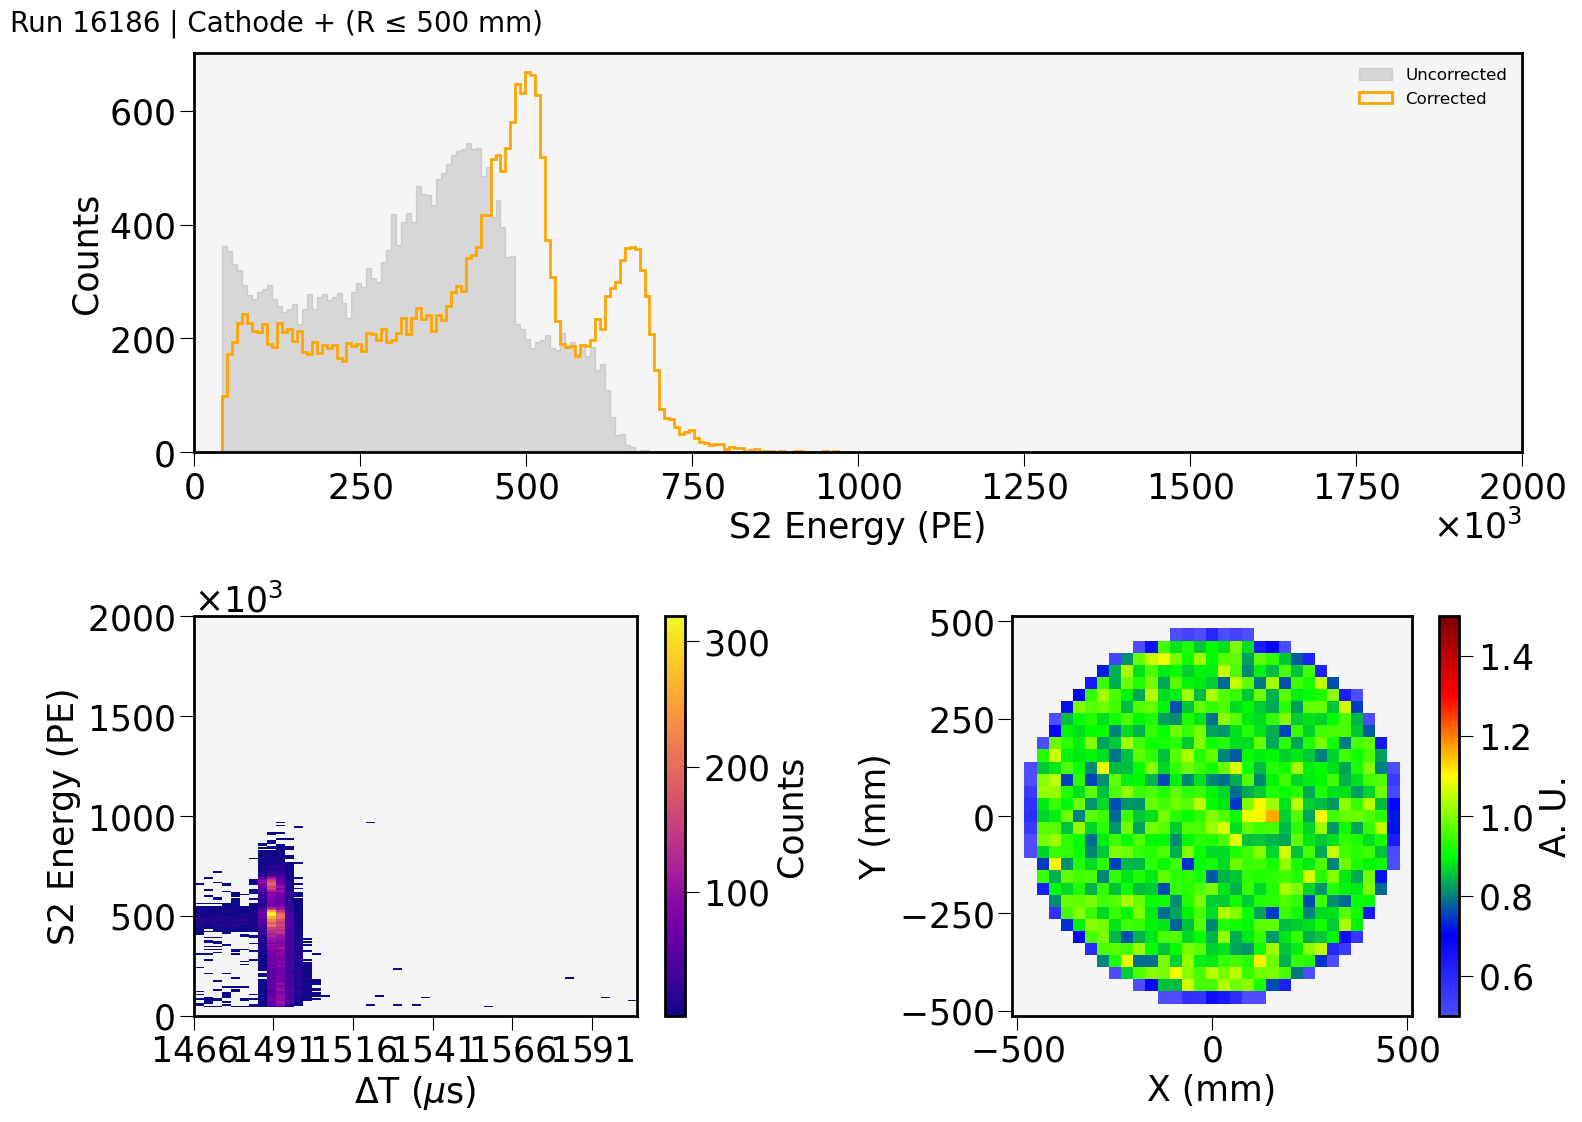

In [57]:
# Global
rad_lim = 500
e2_lim = 2000e3

for key in SEL_DICT.keys():

    print(f"Run {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Masking
    mask =  EXTRA_INFO[key]['alpha_mask'] & EXTRA_INFO[key]['cath_mask'] & (doro_df['R'] <= rad_lim) #& (EXTRA_INFO[key]['w2_mask'])
    if mask is not None:
        mask_df = doro_df[mask].copy()
    else:
        mask_df = doro_df.copy()
    
    # Variables
    X = mask_df['X']
    Y = mask_df['Y']
    DT  = mask_df['DT']
    E2  = mask_df['S2e']
    E2c = mask_df['S2e_corr']

    # 2D histogram: normalized by corrected DAQ data taking time
    S2e_DT_map, ex, ey = crudo.pt.hist_2D(DT, E2c, x_bins=50, y_bins=125)                        
    S2e_DT_map = np.ma.masked_where(S2e_DT_map == 0, S2e_DT_map)

    # Energy map
    s2e_map, ex_map, ey_map = crudo.pt.mapping(X, Y, wei=E2c, bin_scale=2, max_limit=crudo.pt.N100_rad, norm=True)
    s2e_map = np.ma.masked_where(s2e_map==0, s2e_map)

    # ----- Plotting ----- #
    fig = plt.figure(figsize=(16, 12))
    gs = GridSpec(2, 2, figure=fig)

    ax_top = fig.add_subplot(gs[0, :])
    ax_bottom_left = fig.add_subplot(gs[1, 0])
    ax_bottom_right = fig.add_subplot(gs[1, 1])

    # Upper left
    ax_top.hist(E2, bins=ey, histtype='stepfilled', lw=1.0, color='grey', alpha=0.25, ec='grey', label='Uncorrected')
    ax_top.hist(E2c, bins=ey, histtype='step', lw=2.0, color='orange', alpha=1.0, ec='orange', label='Corrected')
    ax_top.set_xlabel('S2 Energy (PE)')
    ax_top.set_ylabel('Counts')
    ax_top.set_xlim(0, e2_lim)
    # ax_top.set_yscale('log')
    ax_top.ticklabel_format(axis='x', style='sci', scilimits=(3,3))
    ax_top.legend(loc='upper right', fontsize=12, facecolor='none')
    ax_top.set_facecolor('whitesmoke')

    # Lower left
    pcm = ax_bottom_left.pcolormesh(ex, ey, S2e_DT_map.T, cmap='plasma', shading='auto')
    cbar = fig.colorbar(pcm, ax=ax_bottom_left, label='Counts')
    ax_bottom_left.set_xlabel('$\Delta$T ($\mu$s)')
    ax_bottom_left.set_ylabel('S2 Energy (PE)')
    ax_bottom_left.set_xlim(ex[0], ex[-1])
    ax_bottom_left.set_ylim(0, e2_lim)
    ax_bottom_left.set_xticks(np.arange(int(ex[0]), int(ex[-1]), 25))
    ax_bottom_left.ticklabel_format(axis='y', style='sci', scilimits=(3,3))
    ax_bottom_left.set_facecolor('whitesmoke')

    # Lower right
    pcm = ax_bottom_right.pcolormesh(ex_map, ey_map, s2e_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.5, vmax=1.5)
    cbar = fig.colorbar(pcm, ax=ax_bottom_right, label='A. U.')
    ax_bottom_right.set_xlabel('X (mm)')
    ax_bottom_right.set_ylabel('Y (mm)')
    ax_bottom_right.set_aspect('equal', adjustable='box')
    ax_bottom_right.set_facecolor('whitesmoke')

    # Single title for the figure
    fig.suptitle(f'Run {key} | Cathode + (R ≤ {rad_lim} mm)', fontsize=20, x=0, y=0.95, ha='left')

    plt.tight_layout()
    plt.show()

# Energy Plots

### $S1$


Run 16186:
  - S1 Height = [61.45, 939.51] PE | 48203 events


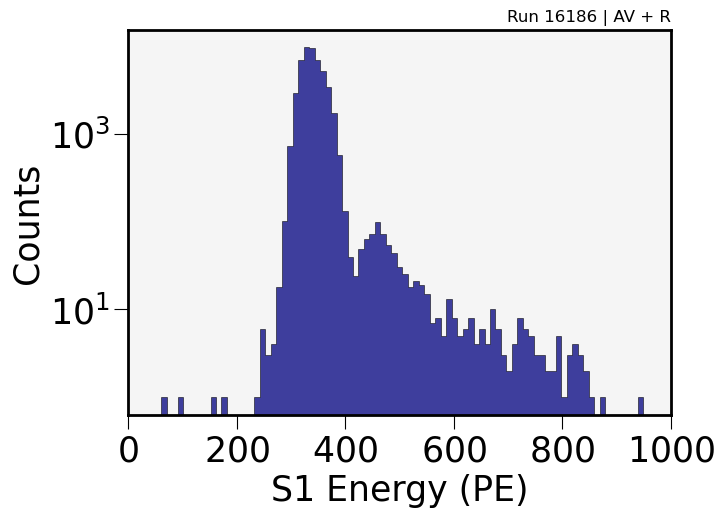

In [64]:
# Params
bins = np.linspace(0, 1e3, 100)
rad_lim = 400
H1_down = 1.8e3;  H1_up = 2.2e3

# Fit?
do_fit = False

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Masking
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask']) & (EXTRA_INFO[key]['rad_mask'])
    # mask = None
    if mask is not None:
        doro_df = doro_df[mask].copy()
    else:
        doro_df = doro_df.copy()

    # Variables
    H1 = doro_df['S1h_corr']
    print(f"  - S1 Height = [{H1.min():.2f}, {H1.max():.2f}] PE | {len(H1)} events")

    # Histogram
    E_counts, E_edges = np.histogram(H1, bins=bins)
    bin_width = np.diff(E_edges).mean()

    plt.stairs(E_counts, E_edges, 
               fill=True, color=crudo.pt.hist_colors[5], alpha=0.75, lw=0.5, ec='black')

    # --- Fit
    if do_fit:

        # Filter the data for the fit
        fit_region_mask =  (H1 >= H1_down) & (H1 <= H1_up)
        H1_fit = H1[fit_region_mask]

        # Compute representative values for the fit
        x_centers, x_err, y_centers, y_err = crudo.ff.prefit_1D(H1_fit, bins=E_edges)
        # Filter out points with zero error (bins with 1 event)
        valid_points = y_err > 0
        x_fit = x_centers[valid_points];      x_fit_err = x_err[valid_points]
        y_fit = y_centers[valid_points];     y_fit_err = y_err[valid_points]

        # Definte the cost function + initial guess
        least_squares = LeastSquares(x_fit, y_fit, y_fit_err, crudo.ff.gauss_func)
        init_guess = [y_fit.max(), x_fit.min(), bin_width]

        # Define the Minuit object
        m = Minuit(least_squares, *init_guess)

        # Minimization process of the cost function and error estimation
        m.migrad()
        m.hesse()

        # Results
        popt = m.values;  perr = m.errors
        print(f'Fit: m = ({popt[0]:.2f} ± {perr[0]:.2f}) PE/μs, b = ({popt[1]:.2f} ± {perr[1]:.2f}) PE')    
        # FIT_PARAMETERS[key]["S1e"] = {"m_CV": popt[0], "m_err": perr[0], "b_CV": popt[1], "b_err": perr[1]}

        # Reduced chi-square
        chi2 = m.fval
        ndof = len(x_fit) - m.nfit
        print(f"     χ² / ndof = {chi2 / ndof:.2f}")

        # Plot data points only for the valid fit region
        plt.errorbar(x_fit, y_fit, xerr=x_fit_err, yerr=y_fit_err, 
                    fmt='o', ms=2, c='black', ecolor='black', elinewidth=0.5)

        # Plot fit line
        # if fit_success:
        fit_y = crudo.ff.gauss_func(x_centers, *popt)
        plt.plot(x_centers, fit_y, color="red")
        # else:
        #     guess_y = crudo.ff.bigauss_func(E_centers, *popt)
        #     plt.plot(E_centers, guess_y, color="orange", ls="--", label="Failed Guess")

    else:   pass

    # --- Styling
    plt.xlabel('S1 Energy (PE)')
    plt.ylabel('Counts')
    plt.xlim(E_edges[0], E_edges[-1])
    plt.yscale('log')
    # plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
    plt.title (f'Run {key} | AV + R', loc='right', fontsize=12)

    # Fit lines
    # plt.axvline(x=H1_down, c='red', ls='--', lw=1.5)
    # plt.axvline(x=H1_up, c='red', ls='--', lw=1.5)

    plt.gca().set_facecolor("whitesmoke")
    # plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/images/S2e_corr_run_{key}.pdf')
    plt.show()

### $S2e$


Run 16186:
  - S2 Energy = [41995.30, 791698.37] PE | 12202 events


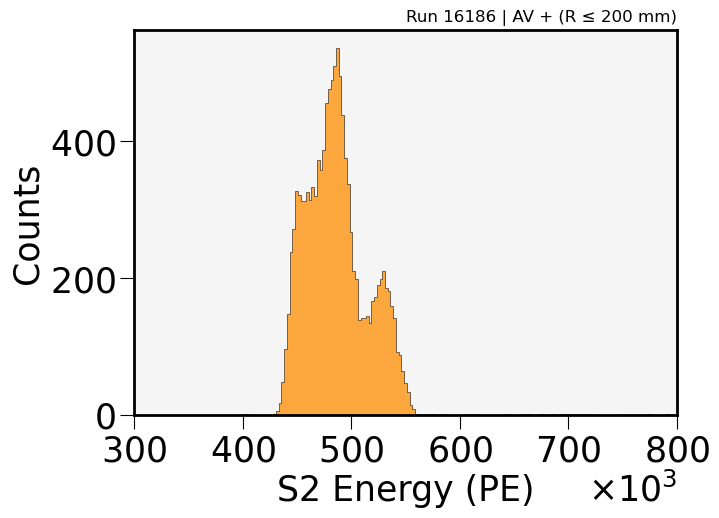

In [66]:
# Params
rad_lim = 200
E1_down = 1.8e3;  E1_up = 2.2e3

# Fit?
do_fit = False

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    run_id = int(key.split('_')[0])
    doro_df = SEL_DICT[key]['doro_df']

    # Masking
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask']) & (doro_df['R'] <= rad_lim)
    # mask = None
    if mask is not None:
        doro_df = doro_df[mask].copy()

    # Variables
    E2 = doro_df['S2e_corr']
    print(f"  - S2 Energy = [{E2.min():.2f}, {E2.max():.2f}] PE | {len(E2)} events")

    # Histogram
    if run_id in [14840, 14739]: bins = np.linspace(600e3, 1500e3, 100)
    else:               bins = np.linspace(300e3, 800e3, 200)
    E_counts, E_edges = np.histogram(E2, bins=bins)
    bin_width = np.diff(E_edges).mean()

    plt.stairs(E_counts, E_edges, 
               fill=True, color=crudo.pt.hist_colors[2], alpha=0.75, lw=0.5, ec='black')

    # --- Fit
    if do_fit:

        # Filter the data for the fit
        fit_region_mask =  (E1 >= E1_down) & (E1 <= E1_up)
        E1_fit = E1[fit_region_mask]

        # Compute representative values for the fit
        x_centers, x_err, y_centers, y_err = crudo.ff.prefit_1D(E1_fit, bins=E_edges)
        # Filter out points with zero error (bins with 1 event)
        valid_points = y_err > 0
        x_fit = x_centers[valid_points];      x_fit_err = x_err[valid_points]
        y_fit = y_centers[valid_points];     y_fit_err = y_err[valid_points]

        # Definte the cost function + initial guess
        least_squares = LeastSquares(x_fit, y_fit, y_fit_err, crudo.ff.gauss_func)
        init_guess = [y_fit.max(), x_fit.min(), bin_width]

        # Define the Minuit object
        m = Minuit(least_squares, *init_guess)

        # Minimization process of the cost function and error estimation
        m.migrad()
        m.hesse()

        # Results
        popt = m.values;  perr = m.errors
        print(f'Fit: m = ({popt[0]:.2f} ± {perr[0]:.2f}) PE/μs, b = ({popt[1]:.2f} ± {perr[1]:.2f}) PE')    
        # FIT_PARAMETERS[key]["S1e"] = {"m_CV": popt[0], "m_err": perr[0], "b_CV": popt[1], "b_err": perr[1]}

        # Reduced chi-square
        chi2 = m.fval
        ndof = len(x_fit) - m.nfit
        print(f"     χ² / ndof = {chi2 / ndof:.2f}")

        # Plot data points only for the valid fit region
        plt.errorbar(x_fit, y_fit, xerr=x_fit_err, yerr=y_fit_err, 
                    fmt='o', ms=2, c='black', ecolor='black', elinewidth=0.5)
        # Plot fit line
        # if fit_success:
        fit_y = crudo.ff.gauss_func(x_centers, *popt)
        plt.plot(x_centers, fit_y, color="red")
        # else:
        #     guess_y = crudo.ff.bigauss_func(E_centers, *popt)
        #     plt.plot(E_centers, guess_y, color="orange", ls="--", label="Failed Guess")

    else:   pass

    # --- Styling
    plt.xlabel('S2 Energy (PE)')
    plt.ylabel('Counts')
    plt.xlim(E_edges[0], E_edges[-1])
    # plt.yscale('log')
    plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
    plt.title (f'Run {key} | AV + (R ≤ {rad_lim} mm)', loc='right', fontsize=12)

    # Fit lines
    # plt.axvline(x=E1_down, c='red', ls='--', lw=1.5)
    # plt.axvline(x=430e3, c='red', ls='--', lw=1.5)
    # plt.axvline(x=460e3, c='red', ls='--', lw=1.5)
    # plt.axvline(x=500e3, c='red', ls='--', lw=1.5)

    plt.gca().set_facecolor("whitesmoke")
    # plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/images/S2e_corr_run_{key}.pdf')
    plt.show()

In [49]:
test_df = SEL_DICT['16166']['doro_df'].copy()
test_df = test_df[(test_df['R'] <= 200) & (test_df['S2e_corr'] >= 430e3) & (test_df['S2e_corr'] <= 460e3)].copy()
test_df

,event,time,s1_peak,s2_peak,nS1,nS2,S1w,S1h,S1e,S1t,...,R,Phi,Xrms,Yrms,S1e_corr,S2e_corr_LT,x_bin,y_bin,S2e_norm_factor,S2e_corr
28,487614,1.792517e+09,0,0,1,1,350.0,248.386078,1529.380737,891450.0,...,57.272515,-1.513042,23.780776,23.972986,2047.691277,446930.193457,8,7,1.012975,441205.534120
68,1744744,1.792565e+09,0,0,1,1,625.0,270.616241,1636.484741,689125.0,...,197.583210,-1.675782,24.378138,23.054058,2006.176485,427497.870983,8,5,0.948281,450813.401909
154,391560,1.792513e+09,0,0,1,1,550.0,292.356079,1799.360596,470200.0,...,140.069583,-0.933450,26.033878,24.296564,2020.548425,444048.508768,9,6,0.988861,449050.667932
157,391588,1.792513e+09,0,0,1,1,475.0,272.747131,1634.005615,677650.0,...,42.626204,-2.297920,22.904111,24.574556,1993.642647,454233.648178,8,7,1.012975,448415.440025
161,36415,1.792500e+09,0,0,1,1,650.0,252.708267,1532.236450,908075.0,...,104.632688,-0.607858,24.225907,23.190551,2066.166700,462396.004832,9,7,1.021131,452827.182581
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
169583,2058385,1.792578e+09,0,0,1,1,350.0,298.653931,1809.043945,435825.0,...,197.077280,-0.343074,26.763542,24.775688,2005.221772,443970.312317,11,7,1.011681,438844.097199
169626,1657943,1.792562e+09,0,0,1,1,600.0,253.600876,1537.568848,915950.0,...,75.924973,1.426740,25.774940,25.325061,2081.780925,445402.578012,8,9,1.019412,436921.073186
169641,1658132,1.792562e+09,0,0,1,1,375.0,186.898575,1161.141113,1473275.0,...,145.770516,-2.188632,24.851744,23.937797,2118.207898,432354.203478,7,6,0.982295,440147.135161
169642,1658139,1.792562e+09,0,0,1,1,625.0,235.494019,1445.019165,1002600.0,...,171.014326,2.336800,26.339332,26.855600,2038.367987,434130.467605,6,10,0.966250,449294.158478


In [50]:
nu_df = SEL_DICT['16166']['doro_df'].copy()
nu_df = nu_df[(nu_df['R'] <= 200) & (nu_df['S2e_corr'] >= 460e3) & (nu_df['S2e_corr'] <= 500e3)].copy()
nu_df

,event,time,s1_peak,s2_peak,nS1,nS2,S1w,S1h,S1e,S1t,...,R,Phi,Xrms,Yrms,S1e_corr,S2e_corr_LT,x_bin,y_bin,S2e_norm_factor,S2e_corr
77,1744828,1.792565e+09,0,0,1,1,350.0,326.190308,1924.251587,274625.0,...,181.668933,2.263096,26.594745,25.924638,2010.526296,450430.811334,6,10,0.966250,466163.854952
84,1744905,1.792565e+09,0,0,1,1,375.0,360.550781,2142.537598,333725.0,...,125.112344,0.788695,27.715742,28.151183,2287.223956,486105.497125,9,9,0.990354,490840.130190
99,770064,1.792527e+09,0,0,1,1,350.0,341.034637,1961.755127,126075.0,...,103.305956,1.957720,29.638300,28.107333,1947.366071,474369.211266,7,10,1.014713,467490.965909
103,770099,1.792527e+09,0,0,1,1,350.0,302.882568,1772.549683,436825.0,...,185.619801,-2.080695,26.150696,25.177821,1964.771859,457789.568731,7,5,0.946236,483800.705782
216,1972545,1.792574e+09,0,0,1,1,325.0,232.229767,1364.180054,1009825.0,...,167.660773,2.393659,24.922184,26.579911,1931.007209,449222.380066,6,10,0.966250,464913.214533
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
169508,1270311,1.792547e+09,0,0,1,1,350.0,204.522156,1182.393188,1200925.0,...,186.761144,0.547556,24.407647,25.104637,1843.394874,470721.396030,11,10,0.953101,493884.158137
169523,1270472,1.792547e+09,0,0,1,1,350.0,289.548798,1733.387085,515525.0,...,27.031267,0.330787,25.565084,23.846997,1981.359349,467193.023145,8,8,1.000000,467193.023145
169544,1432151,1.792553e+09,0,0,1,1,350.0,336.554871,1972.689697,126450.0,...,171.780843,2.350979,26.999505,29.409390,1957.806991,479776.846473,6,10,0.966250,496534.914222
169549,1432207,1.792553e+09,0,0,1,1,350.0,187.363876,1099.333862,1321025.0,...,140.395531,1.969550,26.785441,27.467910,1830.974698,474495.568128,7,10,1.014713,467615.490625


In [53]:
meh_df = SEL_DICT['14840']['doro_df'].copy()
meh_df = meh_df[(meh_df['R'] <= 200)].copy()
meh_df

,event,time,s1_peak,s2_peak,nS1,nS2,S1w,S1h,S1e,S1t,...,R,Phi,Xrms,Yrms,S1e_corr,S2e_corr_LT,x_bin,y_bin,S2e_norm_factor,S2e_corr
97,5217,1.739727e+09,0,0,1,1,950.0,52.759003,1252.453247,1412700.0,...,142.838979,2.535414,26.449548,27.095107,2129.143625,5.440064e+05,6,9,0.932837,5.831743e+05
102,5441,1.739727e+09,0,0,1,1,1025.0,74.805061,2273.708984,268900.0,...,35.953784,-3.083614,27.564641,28.068467,2244.957821,6.950933e+05,7,8,0.955203,7.276920e+05
116,5889,1.739727e+09,0,0,1,1,600.0,187.630783,1141.758545,1273425.0,...,21.612228,-2.376650,25.324990,27.146663,1791.561019,9.859106e+05,8,8,1.000000,9.859106e+05
121,6078,1.739727e+09,0,0,1,1,775.0,179.160095,1038.241699,1422400.0,...,124.127692,1.440044,27.780319,26.580652,1786.018884,9.838345e+05,8,10,0.995938,9.878469e+05
124,6134,1.739727e+09,0,0,1,1,650.0,212.183701,1207.031128,1152900.0,...,91.346307,1.955075,26.739427,26.491161,1768.884034,9.166050e+05,7,9,0.935466,9.798374e+05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31321,248793,1.739779e+09,0,0,1,1,800.0,404.949127,2342.257324,272375.0,...,170.871227,1.471830,31.426392,29.648703,2316.431491,1.254424e+06,8,11,0.923277,1.358665e+06
31347,250018,1.739780e+09,0,0,1,1,850.0,91.183525,2137.410400,471875.0,...,159.168972,1.795216,26.905242,26.608988,2282.534603,5.532593e+05,7,10,0.866631,6.384024e+05
31352,250123,1.739780e+09,0,0,1,1,700.0,200.628891,1144.271362,1249550.0,...,147.335331,1.749108,26.559663,27.151189,1771.894494,9.296921e+05,8,10,0.995938,9.334837e+05
31396,252594,1.739780e+09,0,0,1,1,1000.0,88.926384,2332.322998,270875.0,...,169.412847,2.253671,29.167611,29.126818,2305.336432,9.250523e+05,6,10,0.947395,9.764172e+05


In [124]:
# # Params
# rad_lim = 400
# dt_lim = 300
# E_min = 400e3
# E_max = 1300e3
# n_bins = np.linspace(E_min, E_max, 100)

# plt.figure(figsize=(10, 6))

# for i, key in enumerate(SEL_DICT.keys()):

#     print(f"\nRun {key}:")
#     doro_df = SEL_DICT[key]['doro_df']
#     gate_volt = RUNS_INFO_DF.loc[RUNS_INFO_DF['run_number'] == int(key.split('_')[0]), 'gate_voltage'].values[0] / 1e3

#     # Variables
#     E2 = doro_df['S2e_corr']
#     DT = doro_df['DT']
#     R  = np.sqrt(doro_df['X']**2 + doro_df['Y']**2)
#     print(f"  - S2 Energy = [{E2.min():.2f}, {E2.max():.2f}] PE")

#     # Masking
#     mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask']) & (R <= rad_lim) & (DT >= dt_lim)
#     # mask = None
#     if mask is not None:
#         E2 = E2[mask]

#     # Histogram
#     E_counts, E_edges = np.histogram(E2, bins=n_bins)
#     bin_width = np.diff(E_edges).mean()

#     plt.stairs(E_counts, E_edges, 
#                fill=False, lw=1.5, ec=crudo.pt.hist_colors[i], label=f'Run {key} | {gate_volt:.1f} kV')

# # --- Styling
# plt.xlabel('S2 Energy (PE)')
# plt.ylabel('Counts')
# plt.xlim(E_edges[0], E_edges[-1])
# # plt.xlim(E_min, E_max)
# # plt.yscale('log')
# plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
# plt.title (f'AV + (R ≤ {rad_lim} mm) + (DT ≥ {dt_lim}) μs', loc='right', fontsize=10)
# plt.legend(loc='upper right', fontsize=10, facecolor='none')

# # Lines
# # plt.axvline(x=625e3, c='gray', ls='--', lw=1)

# plt.gca().set_facecolor("whitesmoke")
# # plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/images/S2e_corr_run_{key}.pdf')
# plt.show()

### $S2e$ vs $S1e$

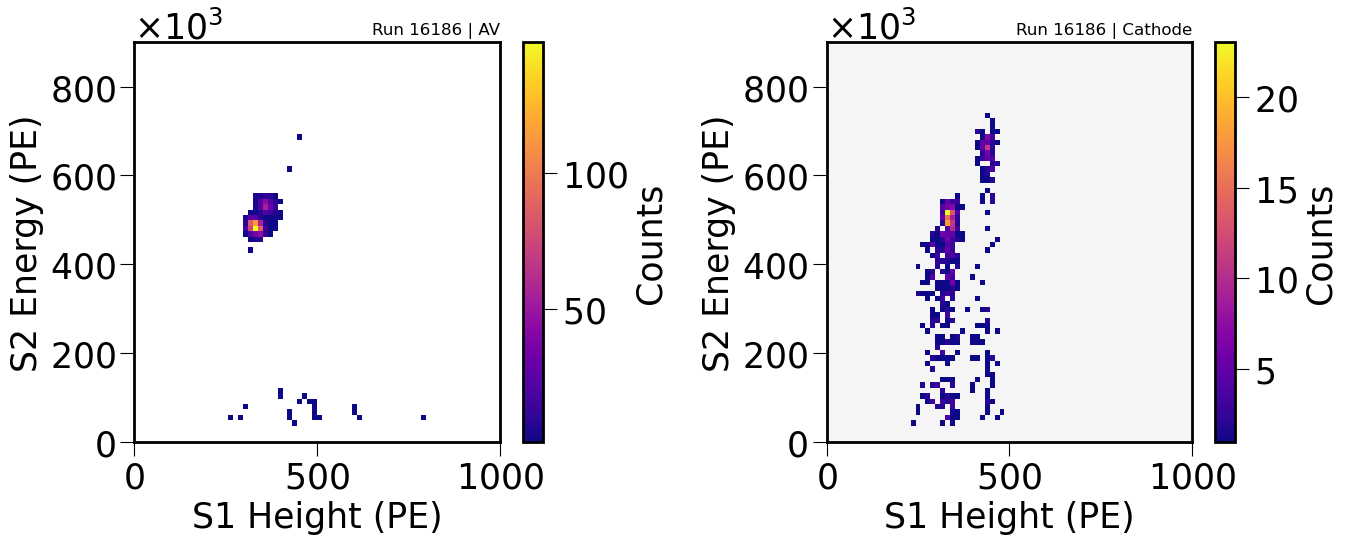

In [69]:
rad_lim = 200
x_bins = np.linspace(0, 1e3, 75)
y_bins = np.linspace(0, 900e3, 75)

for key in SEL_DICT.keys():

    doro_df = SEL_DICT[key]['doro_df']

    fig = plt.figure(figsize=(14, 6))
    gs = GridSpec(1, 2, figure=fig)
    ax_left  = fig.add_subplot(gs[0, 0])
    ax_right = fig.add_subplot(gs[0, 1])

    for i, label in enumerate(['AV', 'Cathode']):

        base_mask = (EXTRA_INFO[key]['alpha_mask']) & (doro_df['R'] <= rad_lim) & (EXTRA_INFO[key]['w1_mask'])

        if label == 'AV':
            mask = base_mask & (EXTRA_INFO[key]['AV_Z_mask'])
            ax = ax_left
        else:
            mask = base_mask & (EXTRA_INFO[key]['cath_mask'])
            ax = ax_right

        mask_df = doro_df[mask].copy()

        # Variables    
        H1 = mask_df['S1h_corr']
        E2 = mask_df['S2e_corr']

        # 2D Histogram
        s1e_s2e_map, ex, ey = np.histogram2d(H1, E2, bins=[x_bins, y_bins])
        s1e_s2e_map         = np.ma.masked_where(s1e_s2e_map==0, s1e_s2e_map)

        # Plot
        pcm = ax.pcolormesh(ex, ey, s1e_s2e_map.T, cmap='plasma', shading='auto')
        plt.colorbar(pcm, ax=ax, label='Counts')
        ax.set_xlabel('S1 Height (PE)')
        ax.set_ylabel('S2 Energy (PE)')
        ax.ticklabel_format(axis='y', style='sci', scilimits=(3,3))
        # ax.set_yticks(ey[::10])
        ax.set_title(f'Run {key} | {label}', loc='right', fontsize=12)

    plt.gca().set_facecolor("whitesmoke")
    plt.tight_layout()
    plt.show()

# Run Stability

## $S2e$ / NSiPM

In [38]:
SEL_DICT['16047_20260727']['doro_df'].columns

Index(['event', 'time', 's1_peak', 's2_peak', 'nS1', 'nS2', 'S1w', 'S1h',
       'S1e', 'S1t', 'S2w', 'S2h', 'S2e', 'S2q', 'S2t', 'qmax', 'Nsipm', 'DT',
       'Z', 'Zrms', 'X', 'Y', 'R', 'Phi', 'Xrms', 'Yrms', 'run_id', 'S1e_corr',
       'S2e_corr_LT', 'x_bin', 'y_bin', 'S2e_norm_factor', 'S2e_corr'],
      dtype='object')


Run 16186:
  S2e / # SiPMs = [1164.54, 6047.43] PE


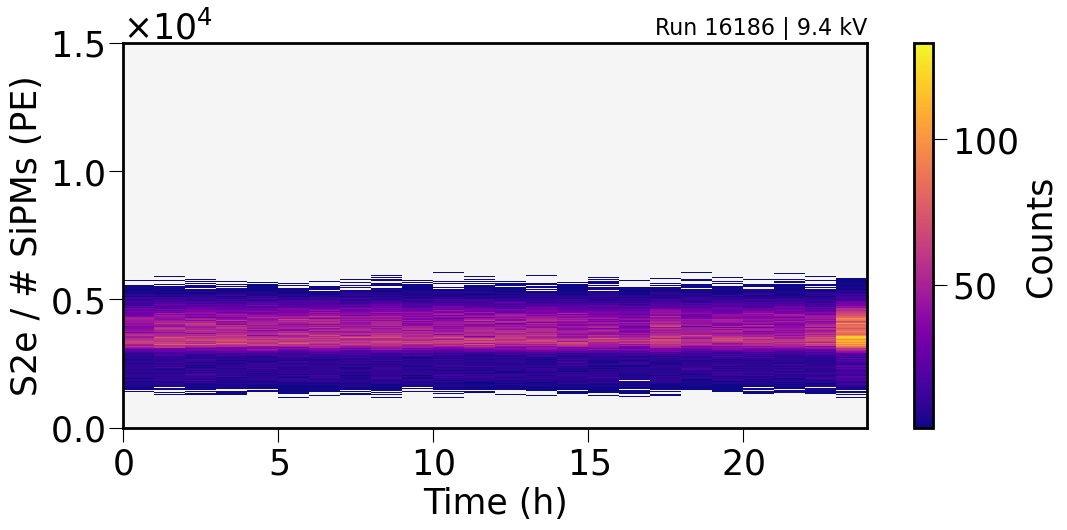

In [70]:
# x_bins = 24  # 24 bins, one for each hour
y_bins = 200

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']
    gate_volt = RUNS_INFO_DF.loc[RUNS_INFO_DF['run_number'] == int(key.split('_')[0]), 'gate_voltage'].values[0] / 1e3

    # Variables
    time = doro_df['time'] - doro_df['time'].min()    # Normalize time to start at 0
    time = (time / 3600).astype(int)                # Convert time to hours
    E2     = doro_df['S2e']
    n_sipm = doro_df['Nsipm']

    # Mask
    mask = (n_sipm > 0) 

    time = time[mask]
    E2     = E2[mask]
    n_sipm = n_sipm[mask]

    y_val = E2 / n_sipm
    print(f"  S2e / # SiPMs = [{y_val.min():.2f}, {y_val.max():.2f}] PE")

    # 2D Histogram
    ex = np.arange(time.min(), time.max(), 1.0)
    map_2d, ex, ey = np.histogram2d(time, y_val, bins=[ex, y_bins], range=[None, [y_val.min(), y_val.max()]])
    map_2d         = np.ma.masked_where(map_2d==0, map_2d)

    # Plot
    plt.figure(figsize=(12, 5))
    plt.pcolormesh(ex, ey, map_2d.T, cmap='plasma', shading='auto')
    plt.colorbar(label='Counts')
    plt.xlabel('Time (h)')
    # plt.xticks(ticks=np.arange(0, 25, 2), labels=[f"{i}" for i in range(0, 25, 2)])
    plt.ylabel('S2e / # SiPMs (PE)')
    plt.ylim(0, 15e3)
    plt.ticklabel_format(axis='y', style='sci', scilimits=(-1, 0))
    plt.title (f'Run {key} | {gate_volt:.1f} kV', loc='right', fontsize=16) 

    plt.gca().set_facecolor("whitesmoke")
    plt.show()


Run 16047_20260727:


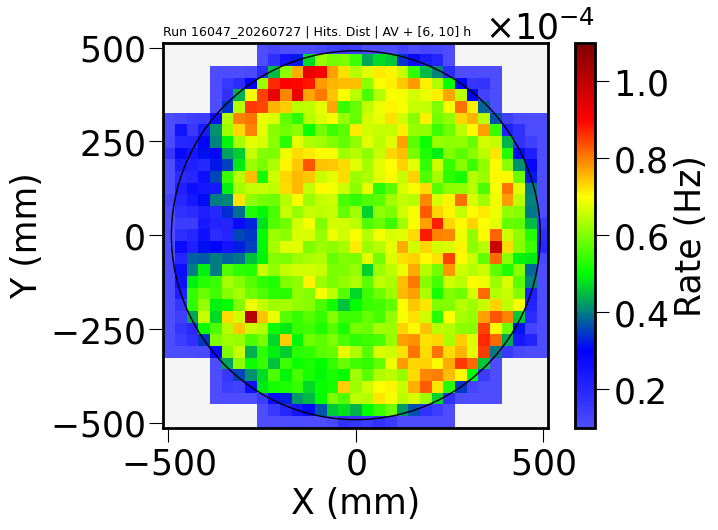


Run 16057_20260727:


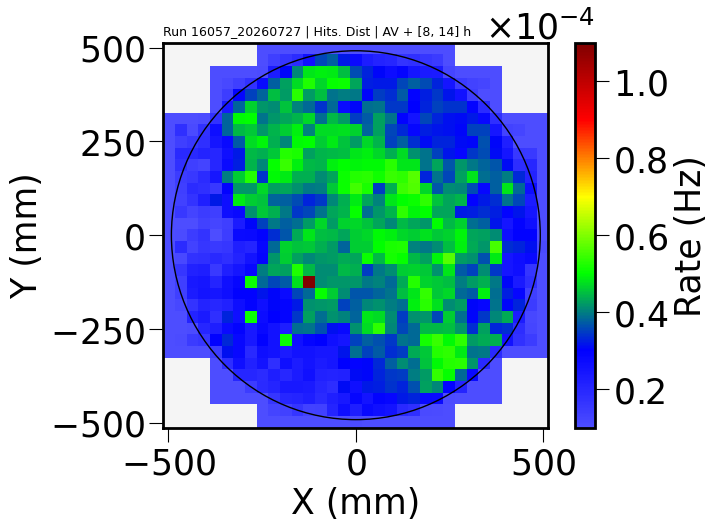

In [59]:
times_47 = [6, 10]
times_57 = [8, 14]

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    soph_df = SEL_DICT[key]['soph_df']

    # Variables  
    X = soph_df['X']
    Y = soph_df['Y']
    Z = soph_df['Z']
    time = ((soph_df['time'] - soph_df['time'].min()) / 3600).astype(int)

    if   key == '16047_20260727': t_min, t_max = times_47
    elif key == '16057_20260727': t_min, t_max = times_57

    # Masking
    mask = (Z >= 0) & (Z <= EXTRA_INFO[key]['cath_lim']) & (time >= t_min) & (time <= t_max)
    X_mask = X[mask]
    Y_mask = Y[mask]

    # Map
    xy_map, ex, ey = crudo.pt.mapping(X_mask, Y_mask, bin_scale=2, max_limit=crudo.pt.N100_rad, pos=True, norm=True)
    xy_map = xy_map / ((t_max - t_min) * 3600)      # Normalize by time interval to get rate
    xy_map = np.ma.masked_where(xy_map==0, xy_map)

    # Plot
    plt.pcolormesh(ex, ey, xy_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.1e-4, vmax=1.1e-4)
    plt.colorbar(label='Rate (Hz)', shrink=1.0)
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.title (f'Run {key} | Hits. Dist | AV + [{t_min}, {t_max}] h', loc='left', fontsize=9) 

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    plt.show()

## Lifetime

In [ ]:
# Global
Date      = []
Date_err  = []
Lifet     = []
Lifet_err = []
Lyield    = []
Lyield_err     = []
Run_number = []

def const_func(x, b):
    return crudo.ff.linear_func(x, 0, b)


for key in SEL_DICT.keys():

    print(f"Run {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    Run_number.append(key)

    # Variables
    Time = doro_df['time']

    # Mean date + error for each run
    date_CV    = Time.mean()
    Date.append(date_CV)
    date_error = Time.sem()
    Date_err.append(date_error)

    # Retrieve lifetime fit value   
    LT_CV    = FIT_PARAMETERS[key]["S2"]["tau_CV"]  / 1e3     # In [ms]
    Lifet.append(LT_CV)
    LT_error = FIT_PARAMETERS[key]["S2"]["tau_err"] / 1e3
    Lifet_err.append(LT_error)

    #
    LY_CV    = FIT_PARAMETERS[key]["S2"]["N0_CV"]  # In [PE/μs]
    Lyield.append(LY_CV)
    LY_error = FIT_PARAMETERS[key]["S2"]["N0_err"]
    Lyield_err.append(LY_error)

    
    

Run 16103:
Run 16104:
Run 16105:


In [115]:
FIT_PARAMETERS

{'16103': {'S1e': {'m_CV': 0.6799226964665488,
   'm_err': 0.0018216639740884148,
   'b_CV': 1041.490920472767,
   'b_err': 1.5219338269503007},
  'S2e': {'N0_CV': 644230.8797011332,
   'N0_err': 525.3620892261587,
   'tau_CV': 32516.541604990995,
   'tau_err': 993.0641541494789}},
 '16104': {'S1e': {'m_CV': 0.6782881041061506,
   'm_err': 0.0018689511473911462,
   'b_CV': 1039.9055578227953,
   'b_err': 1.538204026718317},
  'S2e': {'N0_CV': 643648.76776812,
   'N0_err': 511.8153650933478,
   'tau_CV': 31770.475327364507,
   'tau_err': 941.781561090721}},
 '16105': {'S1e': {'m_CV': 0.6764491279190805,
   'm_err': 0.0018857356057837885,
   'b_CV': 1038.889381105229,
   'b_err': 1.5904297884443868},
  'S2e': {'N0_CV': 642118.4002646587,
   'N0_err': 517.0051705699576,
   'tau_CV': 32160.371923613184,
   'tau_err': 963.9431226951505}}}

No handles with labels found to put in legend.


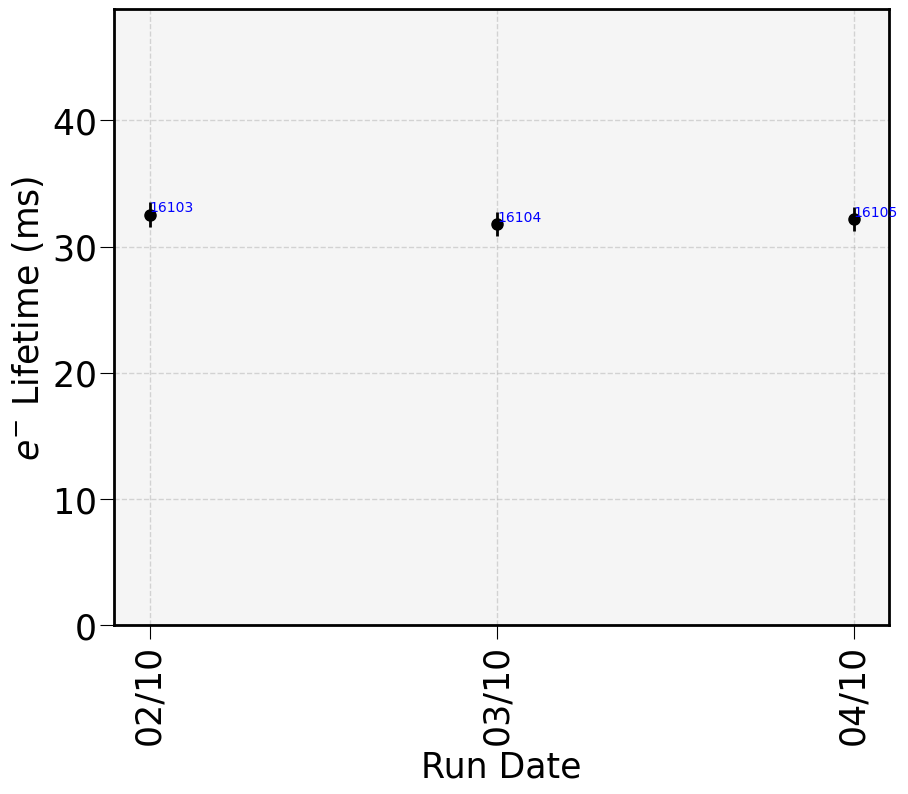

In [120]:
# ----- Plotting ----- #
# plt.figure(figsize=(10, 5))
# Data
plt.errorbar(Date, Lifet, xerr=Date_err, yerr=Lifet_err, fmt='o', c='black', ecolor='black', zorder=2)
for x, y, run_id in zip(Date, Lifet, Run_number):
    plt.text(x, y, str(run_id), fontsize=10, ha='left', va='bottom', color='blue')  # Run number near the point

# Fits
# plt.plot(x_fit[0], y_fit[0], color='blue', ls='-', lw=1.5, label=f'Constant Fit\nχ² / ndof = {chi2[0] / ndof[0]:.2f}', zorder=3)
# plt.plot(x_fit[1], y_fit[1], color='orange', ls='--', label=f'Linear Fit\nχ² / ndof = {chi2[1] / ndof[1]:.2f}')

# Important dates
# plt.axvline(x=1737975600, c='red', ls='--', lw=1.0)
# plt.text(1738030000-1e4, 2.5, 'Hot-getter', fontsize=12, c='red', va='bottom',  ha='right',  rotation=90)

# ----- Styling ----- #
plt.xlabel('Run Date')
x_labels = [crudo.ut.epoch_converter(t, h=False) for t in Date]  # Convert x-axis bin edges to readable time format
plt.xticks(Date, x_labels, rotation=90, ha='center')
plt.ylim(0, 1.5 * max(Lifet))
plt.ylabel(r'$e^{-}$ Lifetime (ms)')
# plt.title(r'$e^{-}$ Lifetime Evolution')
plt.legend(loc='upper right', fontsize=12, facecolor='none')

plt.grid(True)
plt.gca().set_facecolor("whitesmoke")
# plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Radon_LPR/images/Lifetime_Evolution.pdf')
# plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Rn_analysis/images/Lifetime_Evolution.pdf')
plt.show()

## Light Yield

No handles with labels found to put in legend.


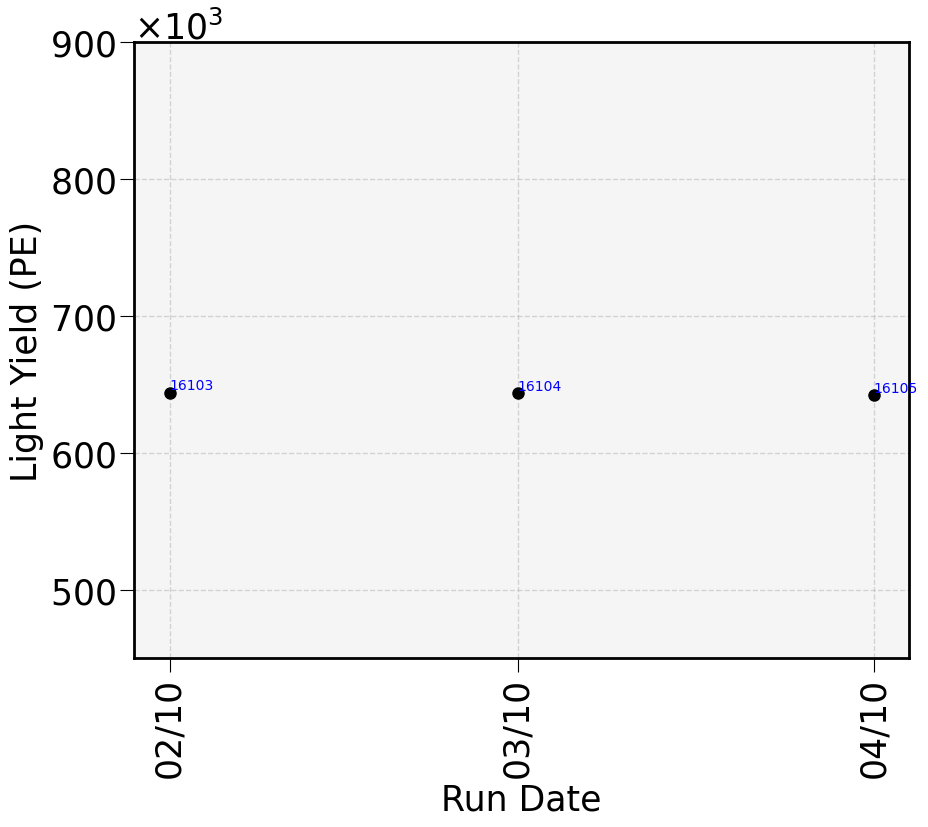

In [151]:
# ----- Plotting ----- #
# plt.figure(figsize=(10, 5))
# Data
plt.errorbar(Date, Lyield, xerr=Date_err, yerr=Lyield_err, fmt='o', c='black', ecolor='black', zorder=2)
for x, y, run_id in zip(Date, Lyield, Run_number):
    plt.text(x, y, str(run_id), fontsize=10, ha='left', va='bottom', color='blue')  # Run number near the point

# Fits
# plt.plot(x_fit[0], y_fit[0], color='blue', ls='-', lw=1.5, label=f'Constant Fit\nχ² / ndof = {chi2[0] / ndof[0]:.2f}', zorder=3)
# plt.plot(x_fit[1], y_fit[1], color='orange', ls='--', label=f'Linear Fit\nχ² / ndof = {chi2[1] / ndof[1]:.2f}')

# Important dates
# plt.axvline(x=1737975600, c='red', ls='--', lw=1.0)
# plt.text(1738030000-1e4, 2.5, 'Hot-getter', fontsize=12, c='red', va='bottom',  ha='right',  rotation=90)

# ----- Styling ----- #
plt.xlabel('Run Date')
x_labels = [crudo.ut.epoch_converter(t, h=False) for t in Date]  # Convert x-axis bin edges to readable time format
plt.xticks(Date, x_labels, rotation=90, ha='center')
plt.ylim(450e3, 900e3)
plt.ylabel(r'Light Yield (PE)')
# plt.title(r'$e^{-}$ Lifetime Evolution')
plt.legend(loc='upper right', fontsize=12, facecolor='none')
plt.ticklabel_format(axis='y', style='sci', scilimits=(3, 3))

plt.grid(True)
plt.gca().set_facecolor("whitesmoke")
# plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Radon_LPR/images/Lifetime_Evolution.pdf')
# plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Rn_analysis/images/Lifetime_Evolution.pdf')
plt.show()

In [143]:
FIT_PARAMETERS

{'16103': {'S1e': {'m_CV': 0.6799226964665488,
   'm_err': 0.0018216639740884148,
   'b_CV': 1041.490920472767,
   'b_err': 1.5219338269503007},
  'S2e': {'N0_CV': 644230.8797011332,
   'N0_err': 525.3620892261587,
   'tau_CV': 32516.541604990995,
   'tau_err': 993.0641541494789}},
 '16104': {'S1e': {'m_CV': 0.6782881041061506,
   'm_err': 0.0018689511473911462,
   'b_CV': 1039.9055578227953,
   'b_err': 1.538204026718317},
  'S2e': {'N0_CV': 643648.76776812,
   'N0_err': 511.8153650933478,
   'tau_CV': 31770.475327364507,
   'tau_err': 941.781561090721}},
 '16105': {'S1e': {'m_CV': 0.6764491279190805,
   'm_err': 0.0018857356057837885,
   'b_CV': 1038.889381105229,
   'b_err': 1.5904297884443868},
  'S2e': {'N0_CV': 642118.4002646587,
   'N0_err': 517.0051705699576,
   'tau_CV': 32160.371923613184,
   'tau_err': 963.9431226951505}}}

# Energy Estimator

We need to determine the optimum weight factor $\eta$ and the scale factor $\lambda$ for the new energy estimator using the $S1$ and $S2$ energy values.

In [77]:
# Parameters for the final energy estimator
best_eta    = 0
best_lambda = 0

print(SEL_DICT.keys())

ref_key = '16186'

dict_keys(['16186'])


## $\eta$ Determination

In [85]:
# Global
n_bins = 500

# Storage of the energy resolution values
E_resolution = []
eta_values = np.linspace(0, 1, 50)  # η variation

# Preliminary bounds for the fit
E_min = 1e3
E_max = 30e3

for eta in eta_values:

    print(f"\n--- Processing η = {eta:.4f} ---")

    # Variables
    data = SEL_DICT[ref_key]['doro_df']

    # Masking
    mask = (EXTRA_INFO[ref_key]['alpha_mask']) & (EXTRA_INFO[ref_key]['AV_Z_mask']) & (EXTRA_INFO[ref_key]['rad_mask']) & (EXTRA_INFO[ref_key]['w1_mask'])
    if mask is not None:
        mask_df = data[mask].copy()
    else:
        mask_df = data.copy()

    E1_corr = mask_df['S1h_corr']
    E2_corr = mask_df['S2e_corr']
    E_total = E1_corr + (E2_corr * eta)     # Energy estimator

    # Histogram
    E_counts, E_edges = np.histogram(E_total, bins=n_bins)
    bin_width = np.diff(E_edges).mean()

    # Compute representative values for the entire histogram
    x_values, x_errors, y_values, y_errors = crudo.ff.prefit_1D(E_total, E_edges)

    # 1. INVINCIBLE FIX: Apply both the E_min/E_max region AND the valid error filter simultaneously
    valid_mask = (y_errors > 0)
    x_fit = x_values[valid_mask];  x_err_fit = x_errors[valid_mask]
    y_fit = y_values[valid_mask];  y_err_fit = y_errors[valid_mask]

    # Enough data for fit?
    if len(x_fit) < 6:
        print(f"Warning: Not enough data points in fit region for eta={eta}. Skipping.")
        E_resolution.append(np.nan)
        continue

    # Dynamic peak finding: find peaks in the y_fit data. We use prominence to ignore small noise bumps.
    peaks, _ = find_peaks(y_fit, distance=5, prominence=0.05 * y_fit.max())

    if len(peaks) >= 2:
        # Sort peaks by height (descending) to get the two most prominent ones
        top_peaks_idx = sorted(peaks, key=lambda i: y_fit[i], reverse=True)[:2]
        top_peaks_idx = sorted(top_peaks_idx)   # Sort by x-position: peak 1 is left, peak 2 is right
        
        mu1_guess = x_fit[top_peaks_idx[0]];    A1_guess  = y_fit[top_peaks_idx[0]]
        mu2_guess = x_fit[top_peaks_idx[1]];    A2_guess  = y_fit[top_peaks_idx[1]]
    else:
        print("Dynamic peak finding failed. Using analytical fallback guess.")
        mu1_guess = 1500 + (830e3 * eta);       A1_guess  = y_fit.max() / 2
        mu2_guess = 1750 + (930e3 * eta);       A2_guess  = y_fit.max() / 2

    sigma_guess = bin_width * 4
    p0 = [A1_guess, mu1_guess, sigma_guess, A2_guess, mu2_guess, sigma_guess]
    print(f'Initial values: {np.round(p0, 2)}')

    # We force sigma > 0.001 to guarantee it is strictly positive.
    lower_bounds = [0, E_min, 0.001, 0, E_min, 0.001]
    upper_bounds = [np.inf, E_max, np.inf, np.inf, E_max, np.inf]

    # --- Fit
    try:
        popt, pcov = curve_fit( crudo.ff.bigauss_func, x_fit, y_fit
                              , p0=p0, bounds=(lower_bounds, upper_bounds), maxfev=10000 )
        
        # Ensure peak 1 is always the lower energy peak
        # curve_fit sometimes swaps the parameters. If mu1 > mu2, we swap them back.
        if popt[1] > popt[4]:
            popt = [popt[3], popt[4], popt[5], popt[0], popt[1], popt[2]]  
        print(f'Final values: {np.round(popt, 2)}') 
        
        # --- Energy Resolution
        FWHM = 2.355 * abs(popt[2]) 
        e_res = (FWHM / popt[1]) * 100
        E_resolution.append(e_res)
        print(f'Energy resolution (Peak 1): {e_res:.2f}%')

        fit_success = True

    except RuntimeError:
        print(f'Fit FAILED to converge for eta = {eta:.4f}')
        E_resolution.append(np.nan)
        popt = p0
        fit_success = False

    # ---Plotting
    plt.figure(figsize=(8, 6))

    plt.stairs(E_counts, E_edges, label=f'$\\eta$ = {eta:.4f}', 
               fill=True, color=crudo.pt.hist_colors[2], alpha=0.8, lw=0.5, ec='black')
    # Plot data points only for the valid fit region
    plt.errorbar(x_fit, y_fit, xerr=x_err_fit, yerr=y_err_fit, 
                 fmt='o', ms=2, c='black', ecolor='black', elinewidth=0.5)
    
    # Plot Fit line
    if fit_success:
        fit_y = crudo.ff.bigauss_func(x_values, *popt)
        plt.plot(x_values, fit_y, color="red", label=f"Fit (Res: {e_res:.2f}%)")
    else:
        # Plot the failed guess to debug
        guess_y = crudo.ff.bigauss_func(x_values, *popt)
        plt.plot(x_values, guess_y, color="orange", ls="--", label="Failed Guess")

    # Styling
    plt.xlabel('Energy (PE)')
    # plt.xlim(5500, 9500)
    plt.ylabel('Counts')
    plt.legend(loc='best', fontsize=12)
    plt.gca().set_facecolor("whitesmoke")
    plt.tight_layout()
    plt.show()


--- Processing η = 0.0000 ---
Initial values: [114.   325.34   4.28 111.   333.9    4.28]


ValueError: `x0` is infeasible.

#### What's the best $\eta$?

The minimum energy resolution is nan% at η = 0.0000


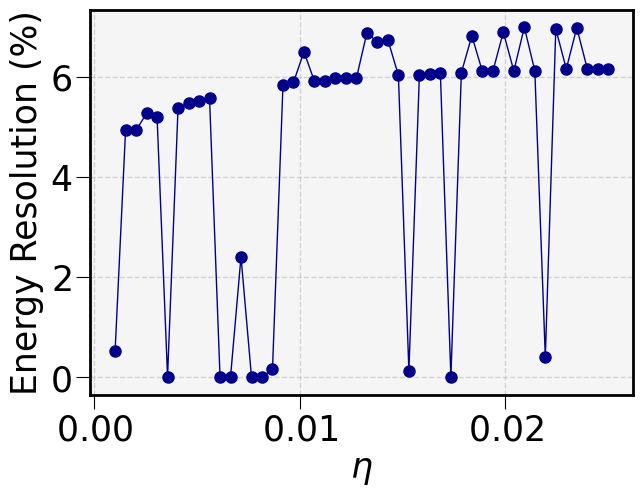

In [83]:
# Find the minimum energy resolution and corresponding eta value
min_index = np.argmin(E_resolution)
Best_eta = eta_values[min_index]
Best_res = E_resolution[min_index]

print(f"The minimum energy resolution is {Best_res:.2f}% at η = {Best_eta:.4f}")

# Store information
# ANA_DATA['High_Rn']['eta_CV'] = Best_eta
# ANA_DATA['Low_Rn']['eta_CV']  = Best_eta

# Plot
# plt.figure(figsize=(8, 6))
plt.plot(eta_values, E_resolution, c='darkblue', marker='o')
plt.scatter([Best_eta], [Best_res], c='red', zorder=3)
plt.xlabel('$\\eta$')
plt.ylabel('Energy Resolution (%)')
# plt.title('Weight Factor Determination')

plt.grid(True)
plt.gca().set_facecolor('whitesmoke')
plt.show()

## $\lambda$ Determination

### High-Rn

Dynamic Peak Finder: Found 222Rn peak near 6390 PE

High-Rn - Initial values:
222Rn: N_1 = 1128.00, μ_1 = 6390.18 PE, σ_1 = 45.37 PE

High-Rn - Fit values:
222Rn: N_1 = (1.07e+03 ± 1.04e+01), μ_1 = (6396.04 ± 0.85) PE, σ_1 = (107.75 ± 0.80) PE
222Rn: λ = 0.8740 keV/PE
χ² / ndof = 3.8509


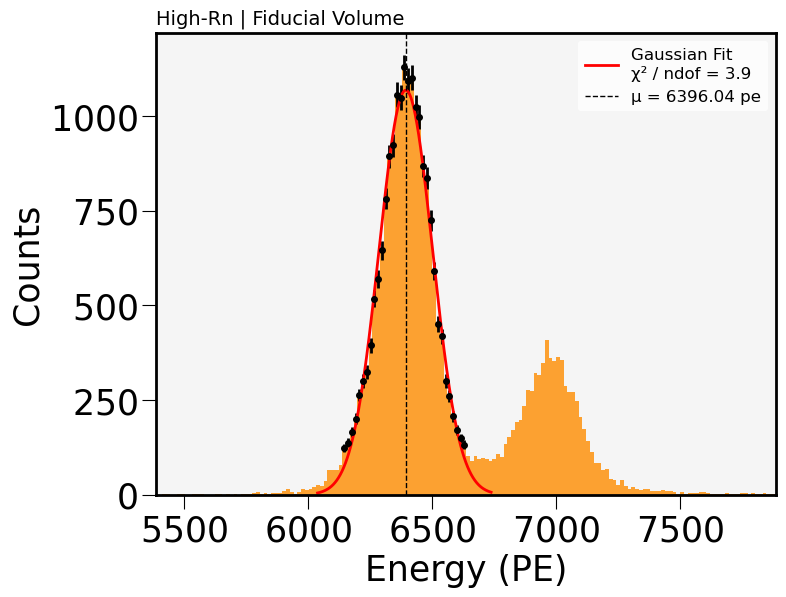

In [ ]:
# Global
n_bins = 1000
E_Rn = 5590.3   # [keV] 222Rn energy peak

# High-Rn info
Rn_data = ANA_DATA['High_Rn']['df']
eta     = ANA_DATA['High_Rn']['eta_CV']

# Variables
E1_corr = Rn_data['S1e_corr']
E2_corr = Rn_data['S2e_corr']
E_total = E1_corr + (E2_corr * eta)  # Energy estimator

# Masking
FV_mask  = ANA_DATA['High_Rn']['FV_mask']
E_mask   = E_total[FV_mask]

# Histogram
E_counts, E_edges = np.histogram(E_mask, bins=n_bins, range=(0, E_total.max()))
bin_width = np.diff(E_edges).mean()
bin_centers = (E_edges[:-1] + E_edges[1:]) / 2

# Compute representative values for the ENTIRE histogram first
E_centers, x_errors, E_values, y_errors = crudo.ff.prefit_1D(E_mask, E_edges)

# --- Dynamic Peak Finding & Windowing
search_mask = (E_centers > 4000) & (y_errors > 0)
x_search = E_centers[search_mask]
y_search = E_values[search_mask]

peaks, _ = find_peaks(y_search, distance=5, prominence=0.05 * y_search.max())

if len(peaks) >= 1:
    top_peaks_idx = sorted(peaks, key=lambda i: y_search[i], reverse=True)[:2]
    left_peak_idx = sorted(top_peaks_idx)[0]
    
    mu_guess = x_search[left_peak_idx];     A_guess  = y_search[left_peak_idx]
    print(f"Dynamic Peak Finder: Found 222Rn peak near {mu_guess:.0f} PE")
else:
    print("Warning: Dynamic peak finding failed. Using fallback.")
    mu_guess = 6400;    A_guess  = 1500

sigma_guess = bin_width * 3

# Define dinamic fit window around the found peak
fit_window = 250 
E_min_fit = mu_guess - fit_window
E_max_fit = mu_guess + fit_window

# Filter data to fit
fit_region_mask = (E_centers >= E_min_fit) & (E_centers <= E_max_fit) & (y_errors > 0)
x_fit = E_centers[fit_region_mask]
y_fit = E_values[fit_region_mask]
y_err_fit = y_errors[fit_region_mask]

# --- Gaussian Fit

# Definte the cost function + initial guess using the dynamically found values
least_squares = LeastSquares(x_fit, y_fit, y_err_fit, crudo.ff.gauss_func)
init_guess    = [A_guess, mu_guess, sigma_guess]
print(f'\nHigh-Rn - Initial values:')
print(f"222Rn: N_1 = {init_guess[0]:.2f}, μ_1 = {init_guess[1]:.2f} PE, σ_1 = {init_guess[2]:.2f} PE")

# Define the Minuit object
m = Minuit(least_squares, A1=init_guess[0], mu1=init_guess[1], sigma1=init_guess[2])

# Apply soft bounds to prevent negative sigma or crazy shifts
# Limit the mean to stay within our fit window, and force sigma to be positive
m.limits['mu1']    = (E_min_fit, E_max_fit)
m.limits['sigma1'] = (0.01, np.inf) 

# Minimization process
m.migrad()
m.hesse()

# Results
popt = m.values;  perr = m.errors
print(f'\nHigh-Rn - Fit values:')
print(f"222Rn: N_1 = ({popt[0]:.2e} ± {perr[0]:.2e}), μ_1 = ({popt[1]:.2f} ± {perr[1]:.2f}) PE, σ_1 = ({popt[2]:.2f} ± {perr[2]:.2f}) PE")

# Lambda value (Calibration Constant)
High_lambda = E_Rn / popt[1]
print(f"222Rn: λ = {High_lambda:.4f} keV/PE")
ANA_DATA['High_Rn']['lambda_CV'] = High_lambda

# Reduced chi-square
chi2 = m.fval
ndof = len(x_fit) - m.nfit
print(f"χ² / ndof = {chi2 / ndof:.4f}")

# ----- Plotting ----- #
plt.figure(figsize=(8, 6))

# Data 
plt.bar(E_edges[:-1], E_counts, width=bin_width, align='edge',
        color=crudo.pt.hist_colors[2], alpha=0.8, lw=1.0)

plt.errorbar(x_fit, y_fit, yerr=y_err_fit, fmt='o', ms=4, c='black', ecolor='black')                                 

# Fit line
x_plot = np.linspace(E_min_fit - 100, E_max_fit + 100, 200)
y_plot = crudo.ff.gauss_func(x_plot, *popt)
plt.plot(x_plot, y_plot, color="red", lw=2.0, label=f'Gaussian Fit\nχ² / ndof = {chi2 / ndof:.1f}')

# Reference line
plt.axvline(x=popt[1], c='black', alpha=1, ls='--', lw=1.0, label=f'μ = {popt[1]:.2f} pe')

# Styling                      
plt.xlabel('Energy (PE)')
plt.xlim(mu_guess - 1e3, mu_guess + 1.5e3)
plt.ylabel('Counts')
# plt.yscale('log')
plt.title(f'High-Rn | Fiducial Volume', fontsize=14, loc='left')
plt.legend(loc='upper right', fontsize=12)    
plt.gca().set_facecolor("whitesmoke")

plt.show()

### Low-Rn

Dynamic Peak Finder: Found 222Rn peak near 7094 PE

Low-Rn - Initial values:
222Rn: N_1 = 1299.00, μ_1 = 7093.93 PE, σ_1 = 130.16 PE

Low-Rn - Fit values:
222Rn: N_1 = (1.26e+03 ± 1.81e+01), μ_1 = (7102.58 ± 1.64) PE, σ_1 = (129.64 ± 1.78) PE
222Rn: λ = 0.7871 keV/PE
χ² / ndof = 1.8335


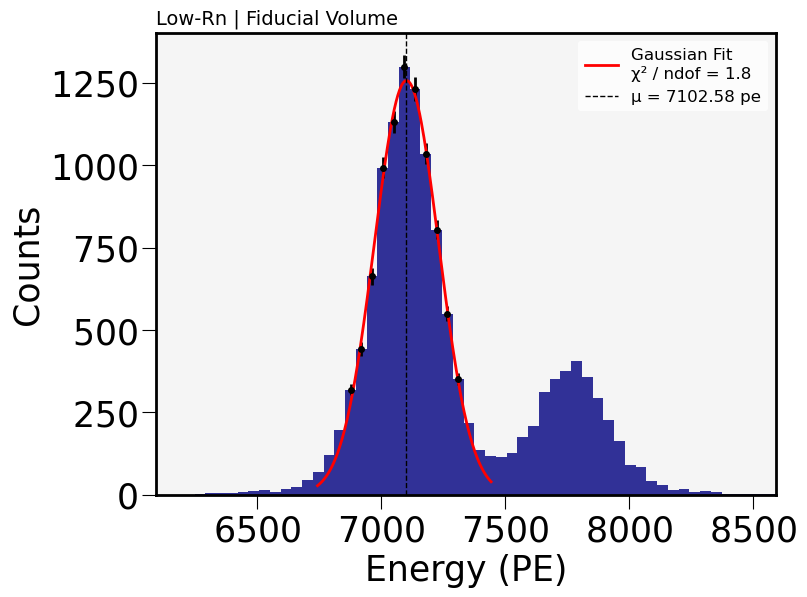

In [ ]:
# Global
n_bins = 1000
E_Rn = 5590.3   # [keV] 222Rn energy peak

# High-Rn info
Rn_data = ANA_DATA['Low_Rn']['df']
eta     = ANA_DATA['Low_Rn']['eta_CV']

# Variables
E1_corr = Rn_data['S1e_corr']
E2_corr = Rn_data['S2e_corr']
E_total = E1_corr + (E2_corr * eta)  # Energy estimator

# Masking
FV_mask  = ANA_DATA['Low_Rn']['FV_mask']
E_mask   = E_total[FV_mask]

# Histogram
E_counts, E_edges = np.histogram(E_mask, bins=n_bins, range=(0, E_total.max()))
bin_width = np.diff(E_edges).mean()
bin_centers = (E_edges[:-1] + E_edges[1:]) / 2

# Compute representative values for the ENTIRE histogram first
E_centers, x_errors, E_values, y_errors = crudo.ff.prefit_1D(E_mask, E_edges)

# --- Dynamic Peak Finding & Windowing
search_mask = (E_centers > 4000) & (y_errors > 0)
x_search = E_centers[search_mask]
y_search = E_values[search_mask]

peaks, _ = find_peaks(y_search, distance=5, prominence=0.05 * y_search.max())

if len(peaks) >= 1:
    top_peaks_idx = sorted(peaks, key=lambda i: y_search[i], reverse=True)[:2]
    left_peak_idx = sorted(top_peaks_idx)[0]
    
    mu_guess = x_search[left_peak_idx];     A_guess  = y_search[left_peak_idx]
    print(f"Dynamic Peak Finder: Found 222Rn peak near {mu_guess:.0f} PE")
else:
    print("Warning: Dynamic peak finding failed. Using fallback.")
    mu_guess = 6400;    A_guess  = 1500

sigma_guess = bin_width * 3

# Define dinamic fit window around the found peak
fit_window = 250 
E_min_fit = mu_guess - fit_window
E_max_fit = mu_guess + fit_window

# Filter data to fit
fit_region_mask = (E_centers >= E_min_fit) & (E_centers <= E_max_fit) & (y_errors > 0)
x_fit = E_centers[fit_region_mask]
y_fit = E_values[fit_region_mask]
y_err_fit = y_errors[fit_region_mask]

# --- Gaussian Fit

# Definte the cost function + initial guess using the dynamically found values
least_squares = LeastSquares(x_fit, y_fit, y_err_fit, crudo.ff.gauss_func)
init_guess    = [A_guess, mu_guess, sigma_guess]
print(f'\nLow-Rn - Initial values:')
print(f"222Rn: N_1 = {init_guess[0]:.2f}, μ_1 = {init_guess[1]:.2f} PE, σ_1 = {init_guess[2]:.2f} PE")

# Define the Minuit object
m = Minuit(least_squares, A1=init_guess[0], mu1=init_guess[1], sigma1=init_guess[2])

# Apply soft bounds to prevent negative sigma or crazy shifts
# Limit the mean to stay within our fit window, and force sigma to be positive
m.limits['mu1']    = (E_min_fit, E_max_fit)
m.limits['sigma1'] = (0.01, np.inf) 

# Minimization process
m.migrad()
m.hesse()

# Results
popt = m.values;  perr = m.errors
print(f'\nLow-Rn - Fit values:')
print(f"222Rn: N_1 = ({popt[0]:.2e} ± {perr[0]:.2e}), μ_1 = ({popt[1]:.2f} ± {perr[1]:.2f}) PE, σ_1 = ({popt[2]:.2f} ± {perr[2]:.2f}) PE")

# Lambda value (Calibration Constant)
High_lambda = E_Rn / popt[1]
print(f"222Rn: λ = {High_lambda:.4f} keV/PE")
ANA_DATA['Low_Rn']['lambda_CV'] = High_lambda

# Reduced chi-square
chi2 = m.fval
ndof = len(x_fit) - m.nfit
print(f"χ² / ndof = {chi2 / ndof:.4f}")

# ----- Plotting ----- #
plt.figure(figsize=(8, 6))

# Data 
plt.bar(E_edges[:-1], E_counts, width=bin_width, align='edge',
        color=crudo.pt.hist_colors[5], alpha=0.8, lw=1.0)

plt.errorbar(x_fit, y_fit, yerr=y_err_fit, fmt='o', ms=4, c='black', ecolor='black')                                 

# Fit line
x_plot = np.linspace(E_min_fit - 100, E_max_fit + 100, 200)
y_plot = crudo.ff.gauss_func(x_plot, *popt)
plt.plot(x_plot, y_plot, color="red", lw=2.0, label=f'Gaussian Fit\nχ² / ndof = {chi2 / ndof:.1f}')

# Reference line
plt.axvline(x=popt[1], c='black', alpha=1, ls='--', lw=1.0, label=f'μ = {popt[1]:.2f} pe')

# Styling                      
plt.xlabel('Energy (PE)')
plt.xlim(mu_guess - 1e3, mu_guess + 1.5e3)
plt.ylabel('Counts')
# plt.yscale('log')
plt.title(f'Low-Rn | Fiducial Volume', fontsize=14, loc='left')
plt.legend(loc='upper right', fontsize=12)    
plt.gca().set_facecolor("whitesmoke")

plt.show()